# Notebook 06 — Nivel III: ecualizador de fase pasatodo
**TP Integrador — Filtros analógicos activos · Grupo 3 · LP Chebyshev I, orden 3 (prototipo construido)**

Consigna (Nivel III): diseñar, simular, construir y medir un ecualizador de fase *all-pass* que modifique o compense el retardo de grupo de un
filtro seleccionado; justificar la función objetivo, la banda útil y la mejora cuantitativa, y verificar que la magnitud sea aproximadamente
constante en la banda de interés.

Contenido:
1. Retardo de grupo del filtro construido; función objetivo y banda útil.
2. Orden del ecualizador: comparación de alternativas.
3. Topología de un solo AO (pasatodo derivado del pasabanda de realimentación múltiple): derivación simbólica y condiciones de pasatodo.
4. Elección de componentes y ajuste de la ganancia con un preset multivuelta.
5. Robustez (Monte Carlo): capacitores nominales, capacitores medidos y ajuste.
6. Respuesta esperada: retardo, magnitud y respuesta al escalón.
7. Netlists de LTspice y verificación.
8. Plan de medición y procesamiento de las mediciones.
9. Exportación para el informe.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import sympy as sp
import scipy
from scipy import optimize, signal
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | SymPy {sp.__version__} | "
      f"Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, RES, LTS, MED = ROOT / 'figuras', ROOT / 'resultados', ROOT / 'ltspice', ROOT / 'mediciones'
MED3 = MED / 'nivel3'
for d_ in (FIG, RES, LTS, LTS / 'resultados', MED3):
    d_.mkdir(exist_ok=True)

AZUL, NARANJA, VERDE, AMARILLO, MAGENTA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6, 'axes.edgecolor': '#6b6b67',
    'axes.linewidth': 0.8, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight'); fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')

def num(x, nd=3):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x
    t = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + t) if x < 0 else t

def ing(x, unidad=''):
    for suf, fac in [('M', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('µ', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= fac * 0.9999:
            return f'{x / fac:.4g} {suf}{unidad}'
    return f'{x:.4g} {unidad}'

def macros_tex(p):
    if not p.exists():
        return {}
    return {m.group(1): float(m.group(2)) for m in re.finditer(r'\\newcommand\{\\(\w+)\}\{([-\d.eE+]+)\}', p.read_text(encoding='utf-8'))}

DATOS = json.load(open(RES / 'componentes.json', encoding='utf-8'))
COMP, PL = DATOS['componentes'], DATOS['plantilla']
FP = PL['fp']
M04 = macros_tex(RES / 'valores_nb04.tex')                                   # medición del filtro (notebook 04)

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | SymPy 1.14.0 | Matplotlib 3.11.2 | pandas 3.0.5


## 1. Retardo de grupo del filtro, función objetivo y banda útil
El filtro a ecualizar es **el prototipo construido**, no el nominal: el ecualizador se arma para ese filtro. Se usa el modelo ajustado a su medición
(notebook 04): $H(s) = \frac{\omega_r}{s+\omega_r}\cdot\frac{\omega_0^2}{s^2+(\omega_0/Q)s+\omega_0^2}$ con $f_r$, $f_0$ y $Q$ ajustados. El retardo de
grupo de una transferencia racional se calcula polo a polo: cada polo $p = -\sigma + j\omega_p$ aporta $\sigma/[\sigma^2 + (\omega-\omega_p)^2]$
y cada cero lo resta (un cero en el semiplano derecho, como los de un pasatodo, suma).

**Banda útil:** la banda de paso de la plantilla, $0 < f \le f_p = 1$ kHz: es la banda que el filtro transmite y donde importa la forma de onda. Por
encima de $f_p$ la señal está atenuada y su retardo no tiene interés.

**Función objetivo:** la variación pico a pico del retardo total en la banda útil,
$$J = \max_{0<f\le f_p} \tau_{\text{tot}}(f) - \min_{0<f\le f_p} \tau_{\text{tot}}(f), \qquad \tau_{\text{tot}} = \tau_{\text{filtro}} + \tau_{\text{ec}},$$
que se minimiza (criterio *minimax*). Un retardo constante solo desplaza la señal en el tiempo y no la deforma; lo que deforma es la **variación**
del retardo, por eso se minimiza la variación y no el valor. Como medida complementaria se informa también el valor eficaz de la desviación
respecto de la media, $J_\text{rms}$.

In [2]:
def tau_raices(polos, ceros, f):
    """Retardo de grupo [s] de una transferencia racional a partir de sus polos y ceros."""
    w = 2 * np.pi * np.asarray(f, float)[..., None]
    tp = sum((-p.real) / (p.real**2 + (w[..., 0] - p.imag)**2) for p in polos)
    tz = sum((-z.real) / (z.real**2 + (w[..., 0] - z.imag)**2) for z in ceros) if len(ceros) else 0.0
    return tp - tz

def polos_filtro(fr, f0, Q):
    w0 = 2 * np.pi * f0
    return [complex(-2 * np.pi * fr, 0)] + list(np.roots([1, w0 / Q, w0**2]))

def tau_filtro(f, fr, f0, Q):
    return tau_raices(polos_filtro(fr, f0, Q), [], f)

def tau_ap2(f, f0, Q):
    """Pasatodo de 2.º orden ideal: dos veces el retardo del denominador."""
    w0 = 2 * np.pi * f0
    return 2 * tau_raices(list(np.roots([1, w0 / Q, w0**2])), [], f)

def tau_ap1(f, fa):
    wa = 2 * np.pi * fa
    return 2 * wa / (wa**2 + (2 * np.pi * np.asarray(f, float))**2)

def J_pp(t):
    return np.ptp(t, axis=0)

def J_rms(t):
    return np.std(t, axis=0)

# Filtro nominal (componentes de diseño, V6/V1 sin Rs) y prototipo (ajuste del notebook 04)
FR_N = 1 / (2 * np.pi * (COMP['R0']) * COMP['C0'])
F0_N = 1 / (2 * np.pi * np.sqrt(COMP['R1'] * COMP['R2'] * COMP['C1'] * COMP['C2']))
Q_N = np.sqrt(COMP['C1'] / COMP['C2']) * np.sqrt(COMP['R1'] * COMP['R2']) / (COMP['R1'] + COMP['R2'])
NOMINAL = (FR_N, F0_N, Q_N)
PROTO = (M04['mFrAj'], M04['mFoAj'], M04['mQAj']) if M04 else NOMINAL
U_PROTO = (M04.get('mUFr', 0.0), M04.get('mUFo', 0.0), M04.get('mUQ', 0.0))
print('Filtro nominal  : fr = %.1f Hz, f0 = %.1f Hz, Q = %.4f' % NOMINAL)
print('Prototipo (ajuste): fr = %.1f Hz, f0 = %.1f Hz, Q = %.4f  (u = %.1f Hz, %.1f Hz, %.4f)' % (PROTO + U_PROTO))

F_B = np.linspace(1, FP, 1000)                     # banda útil
tau_F = tau_filtro(F_B, *PROTO)
J0, J0rms = J_pp(tau_F), J_rms(tau_F)
print(f'Prototipo sin ecualizar: tau(0) = {1e3*tau_F[0]:.3f} ms, tau(1 kHz) = {1e3*tau_F[-1]:.3f} ms, J = {1e3*J0:.3f} ms, J_rms = {1e3*J0rms:.3f} ms')

# Retardo medido del prototipo (fase del Bode, diferencias cada ~0,1 década, como en el notebook 04)
MEDP = None
if (RES / 'mediciones_procesadas.csv').exists():
    md = pd.read_csv(RES / 'mediciones_procesadas.csv'); md = md[md['valido']]
    fm, Fm = md['frecuencia_Hz'].values, np.radians(md['fase_desenrollada_grados'].values)
    paso = np.median(np.diff(np.log10(fm))); kk = max(int(round(0.1 / paso)), 1)
    i_ = np.arange(0, len(fm) - kk)
    MEDP = pd.DataFrame({'f': np.sqrt(fm[i_ + kk] * fm[i_]), 'tau': -(Fm[i_ + kk] - Fm[i_]) / (2 * np.pi * (fm[i_ + kk] - fm[i_]))})

Filtro nominal  : fr = 774.1 Hz, f0 = 1201.1 Hz, Q = 1.5525
Prototipo (ajuste): fr = 786.4 Hz, f0 = 1241.0 Hz, Q = 1.4344  (u = 19.1 Hz, 5.6 Hz, 0.0302)
Prototipo sin ecualizar: tau(0) = 0.292 ms, tau(1 kHz) = 0.414 ms, J = 0.137 ms, J_rms = 0.037 ms


## 2. Orden del ecualizador
Para que $\tau_\text{tot}$ sea plano, el ecualizador debe aportar mucho retardo en baja frecuencia (donde el filtro aporta poco) y poco cerca de
$f_p$ (donde el filtro tiene su pico). Se comparan, optimizando $J$ para el prototipo:
* un pasatodo de **1.er orden**, $\tau = 2\omega_a/(\omega_a^2+\omega^2)$, decreciente;
* **dos** de 1.er orden en cascada;
* un pasatodo de **2.º orden**, $H = (s^2 - (\omega_0/Q)s + \omega_0^2)/(s^2 + (\omega_0/Q)s + \omega_0^2)$, cuyo retardo es decreciente si
  $Q < 1/\sqrt{3}$ y tiene un pico cerca de $\omega_0$ si $Q$ es mayor;
* 2.º orden + 1.er orden.

In [3]:
def optimizar(fun_tau, x0, cotas):
    mejor = None
    rng_ = np.random.default_rng(0)
    for _ in range(12):
        x_ini = [np.exp(rng_.uniform(np.log(a), np.log(b))) for a, b in cotas] if mejor is not None else x0
        r = optimize.minimize(lambda p: J_pp(tau_F + fun_tau(F_B, *p)), x_ini, method='Nelder-Mead',
                              options={'xatol': 1e-6, 'fatol': 1e-12, 'maxiter': 4000})
        if all(a <= v <= b for v, (a, b) in zip(r.x, cotas)) and (mejor is None or r.fun < mejor.fun):
            mejor = r
    return mejor

OPC = {}
OPC['1.er orden'] = (optimizar(lambda f, fa: tau_ap1(f, fa), [1000], [(50, 2e4)]), 1, lambda f, fa: tau_ap1(f, fa))
OPC['2 × 1.er orden'] = (optimizar(lambda f, a, b: tau_ap1(f, a) + tau_ap1(f, b), [1500, 1600], [(50, 2e4)] * 2), 2,
                         lambda f, a, b: tau_ap1(f, a) + tau_ap1(f, b))
OPC['2.º orden'] = (optimizar(lambda f, f0, Q: tau_ap2(f, f0, Q), [940, 0.65], [(100, 1e4), (0.2, 5)]), 1,
                    lambda f, f0, Q: tau_ap2(f, f0, Q))
OPC['2.º + 1.er orden'] = (optimizar(lambda f, f0, Q, fa: tau_ap2(f, f0, Q) + tau_ap1(f, fa), [940, 0.65, 3000],
                                     [(100, 1e4), (0.2, 5), (50, 5e4)]), 2,
                           lambda f, f0, Q, fa: tau_ap2(f, f0, Q) + tau_ap1(f, fa))
filas = [{'ecualizador': 'ninguno', 'AO': 0, 'parámetros': '---', 'J [ms]': 1e3 * J0, 'J_rms [ms]': 1e3 * J0rms, 'mejora': 1.0,
          'tau(0) total [ms]': 1e3 * tau_F[0]}]
for nombre, (r, nao, ft) in OPC.items():
    tt = tau_F + ft(F_B, *r.x)
    filas.append({'ecualizador': nombre, 'AO': nao, 'parámetros': ', '.join(f'{v:.4g}' for v in r.x), 'J [ms]': 1e3 * r.fun,
                  'J_rms [ms]': 1e3 * J_rms(tt), 'mejora': J0 / r.fun, 'tau(0) total [ms]': 1e3 * tt[0]})
TAB_ORDEN = pd.DataFrame(filas).set_index('ecualizador')
TAB_ORDEN.round(4)

,AO,parámetros,J [ms],J_rms [ms],mejora,tau(0) total [ms]
ecualizador,,,,,,
ninguno,0,---,0.1375,0.0370,1.0000,0.2918
1.er orden,1,1139,0.0678,0.0234,2.0284,0.5714
2 × 1.er orden,2,"1544, 1544",0.0610,0.0211,2.2522,0.7040
2.º orden,1,"991.5, 0.6244",0.0053,0.0019,26.1199,0.8059
2.º + 1.er orden,2,"1048, 0.6455, 1521",0.0020,0.0006,69.6051,0.9714


**Elección: pasatodo de 2.º orden con un solo AO.** Reduce $J$ unas quince veces con un único amplificador; los pasatodos de 1.er orden apenas lo
reducen a la mitad, porque su retardo decrece demasiado despacio. Agregar una sección de 1.er orden al de 2.º orden mejora todavía el óptimo
teórico, pero esa mejora no es alcanzable: con componentes de tolerancia real, el $J$ queda limitado por la dispersión de $f_0$ y $Q$ del
ecualizador (sección 5) mucho antes de llegar al óptimo de un solo AO, de modo que el segundo AO no se justifica. El óptimo tiene $Q$ algo mayor
que $1/\sqrt{3}$: el retardo del ecualizador es casi plano hasta unos 600 Hz y cae justo donde sube el del filtro.

Pasatodo óptimo para el prototipo: f0 = 991.47 Hz, Q = 0.6244  ->  J = 0.0053 ms (mejora × 26.1)
Para el filtro nominal sería: f0 = 916.2 Hz, Q = 0.6313; J nominal sin ecualizar = 0.180 ms, con = 0.0129 ms
Ecualizador del prototipo aplicado al filtro nominal: J = 0.0480 ms


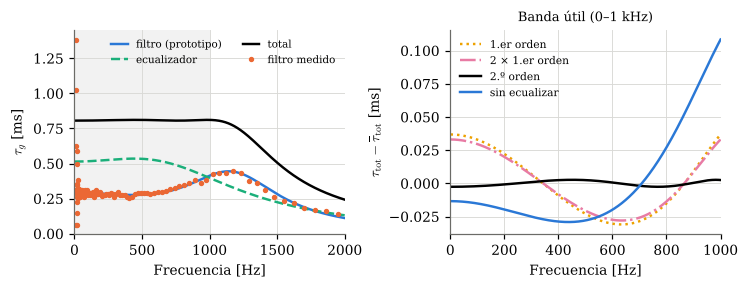

In [4]:
r2 = OPC['2.º orden'][0]
F0_AP, Q_AP = r2.x
J_OPT = r2.fun
print(f'Pasatodo óptimo para el prototipo: f0 = {F0_AP:.2f} Hz, Q = {Q_AP:.4f}  ->  J = {1e3*J_OPT:.4f} ms (mejora × {J0/J_OPT:.1f})')
# Mismo criterio para el filtro nominal (referencia)
tau_FN = tau_filtro(F_B, *NOMINAL)
rN = optimize.minimize(lambda p: J_pp(tau_FN + tau_ap2(F_B, *p)), [920, 0.63], method='Nelder-Mead')
print(f'Para el filtro nominal sería: f0 = {rN.x[0]:.1f} Hz, Q = {rN.x[1]:.4f}; J nominal sin ecualizar = {1e3*J_pp(tau_FN):.3f} ms, con = {1e3*rN.fun:.4f} ms')
print(f'Ecualizador del prototipo aplicado al filtro nominal: J = {1e3*J_pp(tau_FN + tau_ap2(F_B, F0_AP, Q_AP)):.4f} ms')

fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.7))
ft = np.linspace(1, 2000, 2000)
ax = axs[0]
ax.plot(ft, 1e3 * tau_filtro(ft, *PROTO), color=AZUL, label='filtro (prototipo)')
ax.plot(ft, 1e3 * tau_ap2(ft, F0_AP, Q_AP), color=VERDE, ls='--', label='ecualizador')
ax.plot(ft, 1e3 * (tau_filtro(ft, *PROTO) + tau_ap2(ft, F0_AP, Q_AP)), color='k', label='total')
if MEDP is not None:
    ax.plot(MEDP['f'], 1e3 * MEDP['tau'], 'o', ms=2.5, color=NARANJA, label='filtro medido')
ax.axvspan(0, FP, color=GRIS, alpha=0.12, lw=0)
ax.set(xlim=(0, 2000), ylim=(0, 1.45), xlabel='Frecuencia [Hz]', ylabel=r'$\tau_g$ [ms]'); ax.legend(fontsize=6.8, loc='upper right', ncol=2, handlelength=1.6)
ax = axs[1]
for nombre, col, ls in [('1.er orden', AMARILLO, ':'), ('2 × 1.er orden', MAGENTA, '-.'), ('2.º orden', 'k', '-')]:
    r_, _, ft_ = OPC[nombre]
    tt = tau_F + ft_(F_B, *r_.x)
    ax.plot(F_B, 1e3 * (tt - tt.mean()), color=col, ls=ls, label=nombre)
ax.plot(F_B, 1e3 * (tau_F - tau_F.mean()), color=AZUL, label='sin ecualizar')
ax.set(xlim=(0, FP), xlabel='Frecuencia [Hz]', ylabel=r'$\tau_\mathrm{tot} - \overline{\tau}_\mathrm{tot}$ [ms]')
ax.legend(fontsize=7); ax.set_title('Banda útil (0–1 kHz)', fontsize=8.5)
fig.tight_layout(); guardar(fig, 'fig_ec_objetivo'); plt.show()

## 3. Topología: pasatodo de un solo AO
Se usa el pasabanda de realimentación múltiple (Delyiannis–Friend) con una fracción $k$ de la entrada aplicada a la entrada no inversora:

* $V_{in}$ → $R_1$ → nodo A; nodo A → $C_1$ → entrada inversora; nodo A → $C_2$ → salida; entrada inversora → $R_2$ → salida;
* entrada no inversora: divisor $R_a$–$R_b$ desde $V_{in}$, $V_+ = k\,V_{in}$ con $k = R_b/(R_a+R_b)$.

Se deriva la transferencia por análisis nodal con AO ideal ($V_- = V_+$) **antes** de imponer valores.

In [5]:
s = sp.symbols('s')
R1s, R2s, C1s, C2s, ks = sp.symbols('R_1 R_2 C_1 C_2 k', positive=True)
Vi, VA, Vo = sp.symbols('V_i V_A V_o')
Vp = ks * Vi
ecs = [sp.Eq((Vi - VA) / R1s, s * C1s * (VA - Vp) + s * C2s * (VA - Vo)),     # KCL en el nodo A
       sp.Eq(s * C1s * (VA - Vp), (Vp - Vo) / R2s)]                             # KCL en la entrada inversora (V- = V+ = k Vi)
sol = sp.solve(ecs, [VA, Vo], dict=True)[0]
H_ap = sp.simplify(sol[Vo] / Vi)
num_, den_ = sp.fraction(sp.together(H_ap))
P_num, P_den = sp.Poly(sp.expand(num_), s), sp.Poly(sp.expand(den_), s)
a2 = P_den.all_coeffs()[0]
DEN = [sp.simplify(c / a2) for c in P_den.all_coeffs()]
NUM = [sp.simplify(c / a2) for c in P_num.all_coeffs()]
print('Denominador normalizado: s^2 +', DEN[1], '* s +', DEN[2])
print('Numerador normalizado  :', NUM[0], '* s^2 + (', sp.simplify(NUM[1]), ') * s +', NUM[2])
w0_e = sp.sqrt(DEN[2]); Q_e = sp.simplify(w0_e / DEN[1])
print('w0 =', w0_e, '   Q =', Q_e)
# Condición de pasatodo: coeficiente de s del numerador = -k * coeficiente de s del denominador
cond = sp.simplify(NUM[1] + ks * DEN[1])
k_sol = sp.solve(sp.Eq(cond, 0), ks)[0]
print('Condición de pasatodo: k =', sp.simplify(k_sol))
n_ = sp.symbols('n', positive=True)
k_n = sp.simplify(k_sol.subs(C1s, n_ * C2s))
print('Con C1 = n C2 y Q del circuito:', sp.simplify(k_n), ' ;  1/k - 1 =', sp.simplify(1 / k_n - 1))
Qn = sp.simplify(Q_e.subs(C1s, n_ * C2s))
print('Q con C1 = n C2:', Qn)

Denominador normalizado: s^2 + (C_1 + C_2)/(C_1*C_2*R_2) * s + 1/(C_1*C_2*R_1*R_2)
Numerador normalizado  : k * s^2 + ( k/(C_2*R_2) + k/(C_2*R_1) - 1/(C_2*R_1) + k/(C_1*R_2) ) * s + k/(C_1*C_2*R_1*R_2)
w0 = 1/(sqrt(C_1)*sqrt(C_2)*sqrt(R_1)*sqrt(R_2))    Q = sqrt(C_1)*sqrt(C_2)*sqrt(R_2)/(sqrt(R_1)*(C_1 + C_2))
Condición de pasatodo: k = C_1*R_2/(2*C_1*R_1 + C_1*R_2 + 2*C_2*R_1)
Con C1 = n C2 y Q del circuito: R_2*n/(2*R_1*n + 2*R_1 + R_2*n)  ;  1/k - 1 = 2*R_1*(n + 1)/(R_2*n)
Q con C1 = n C2: sqrt(R_2)*sqrt(n)/(sqrt(R_1)*(n + 1))


**Resultado.** El denominador es el del pasabanda de realimentación múltiple,
$D(s) = s^2 + \frac{C_1+C_2}{R_2 C_1 C_2}\,s + \frac{1}{R_1R_2C_1C_2}$, y el numerador es $k\left[s^2 + b_1 s + \omega_0^2\right]$: **el término
independiente coincide siempre con el del denominador** (los ceros y los polos tienen el mismo módulo para cualquier valor de los componentes). La
condición de pasatodo se reduce entonces a una sola ecuación, $b_1 = -\omega_0/Q$, que fija
$$\frac{1}{k} - 1 = \frac{2R_1(C_1+C_2)}{R_2C_1} \;\overset{C_1 = nC_2}{=}\; \frac{2}{Q^2(1+n)}, \qquad Q = \sqrt{\frac{R_2}{R_1}}\,\frac{\sqrt{n}}{1+n}.$$
La ganancia del pasatodo es $k < 1$, constante en todas las frecuencias; conviene $n$ grande para que $k$ se acerque a 1 (con $n = 1$,
$k = Q^2/(1+Q^2) \approx 0{,}29$). Como $k$ no aparece en el denominador, **ajustar $k$ con un preset corrige el error de magnitud sin mover
$\omega_0$ ni $Q$**: es el ajuste natural de este circuito.

Si $b_1 = -(1-\varepsilon)\,\omega_0/Q$, la magnitud vale $k$ en continua y en alta frecuencia y $k(1-\varepsilon)$ en $\omega_0$: el error de
magnitud es una "campana" centrada en $f_0$ de $20\log_{10}(1-\varepsilon)$ dB.

In [6]:
try:
    import schemdraw
    import schemdraw.elements as elm
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'schemdraw'], check=True)
    import schemdraw
    import schemdraw.elements as elm

def esquema_ecualizador():
    schemdraw.config(fontsize=11, lw=1.1)
    with schemdraw.Drawing(show=False) as d:
        d.config(unit=2.4)
        ent = d.add(elm.Dot(open=True).label('$v_e$ (6)', loc='left'))
        d.add(elm.Resistor().right().label('$R_1$', loc='bottom'))
        nA = d.add(elm.Dot().label('A (7)', loc='bottom', ofst=(0.1, -0.05)))
        d.add(elm.Capacitor().right().label('$C_1$', loc='bottom'))
        n8 = d.add(elm.Dot().label('8', loc='bottom', ofst=(0.15, -0.05)))
        d.add(elm.Line().right(0.6))
        u = d.add(elm.Opamp(leads=True).right().anchor('in1').label('TL081', loc='center', fontsize=9))
        d.add(elm.Line().right(0.8).at(u.out))
        no = d.add(elm.Dot())
        d.add(elm.Line().right(0.8))
        d.add(elm.Dot(open=True).label('$v_s$ (9)', loc='right'))
        # R2: 8 -> salida, por arriba
        d.add(elm.Line().at(n8.center).up(1.6))
        d.add(elm.Resistor().tox(no.center).label('$R_2$', loc='top'))
        d.add(elm.Line().toy(no.center))
        # C2: A -> salida, lazo exterior
        d.add(elm.Line().at(nA.center).up(3.4))
        d.add(elm.Capacitor().tox(no.center).label('$C_2$', loc='top'))
        d.add(elm.Line().toy(n8.center[1] + 1.6))
        d.add(elm.Dot())
        # divisor k: Ra desde la entrada, Rb + preset a masa
        d.add(elm.Line().at(ent.center).down(2.8))
        d.add(elm.Resistor().right().label('$R_a$', loc='bottom'))
        n10 = d.add(elm.Dot().label('10', loc='top', ofst=(0.2, 0.05)))
        d.push()
        d.add(elm.Resistor().down(2.2).label('$R_b$', loc='bottom'))
        d.add(elm.Potentiometer().down(2.2).label('preset', loc='bottom'))
        d.add(elm.Ground())
        d.pop()
        d.add(elm.Line().tox(u.in2[0] - 0.6)); d.add(elm.Line().toy(u.in2)); d.add(elm.Line().tox(u.in2))
        d.save(str(FIG / 'fig_ec_esquema.pdf')); d.save(str(FIG / 'fig_ec_esquema.png'), dpi=200)
esquema_ecualizador()

In [7]:
fH = sp.lambdify([s, R1s, R2s, C1s, C2s, ks], H_ap, 'numpy')
def H_ec(f, R1, R2, C1, C2, k):
    return fH(2j * np.pi * np.asarray(f, float), R1, R2, C1, C2, k)

def k_pasatodo(R1, R2, C1, C2):
    return 1 / (1 + 2 * R1 * (C1 + C2) / (R2 * C1))

def tau_ec(f, R1, R2, C1, C2, k):
    a1 = (C1 + C2) / (R2 * C1 * C2); a0 = 1 / (R1 * R2 * C1 * C2)
    b1 = (k * (C1 * R1 + C1 * R2 + C2 * R1) - C1 * R2) / (k * C1 * C2 * R1 * R2)
    polos = np.roots([1, a1, a0]); ceros = np.roots([1, b1, a0])
    return tau_raices(list(polos), list(ceros), f)

# Sensibilidades de w0, Q y del error de pasatodo
SENS = {}
eps_e = sp.simplify(1 + NUM[1] / (ks * DEN[1]))           # b1 = -(1 - eps) * w0/Q  ->  eps = 1 + b1/(w0/Q)
for P, nombre in [(w0_e, 'w0'), (Q_e, 'Q')]:
    SENS[nombre] = {str(x): sp.simplify(sp.diff(P, x) * x / P) for x in (R1s, R2s, C1s, C2s)}
SENS['eps'] = {str(x): sp.simplify(sp.diff(eps_e, x) * x) for x in (R1s, R2s, C1s, C2s, ks)}   # d eps / (dx/x)
for k_, v in SENS.items():
    print(k_, v)

w0 {'R_1': -1/2, 'R_2': -1/2, 'C_1': -1/2, 'C_2': -1/2}
Q {'R_1': -1/2, 'R_2': 1/2, 'C_1': (-C_1 + C_2)/(2*(C_1 + C_2)), 'C_2': (C_1 - C_2)/(2*(C_1 + C_2))}
eps {'R_1': C_1*R_2*(1 - k)/(R_1*k*(C_1 + C_2)), 'R_2': C_1*R_2*(k - 1)/(R_1*k*(C_1 + C_2)), 'C_1': C_1*C_2*R_2*(k - 1)/(R_1*k*(C_1**2 + 2*C_1*C_2 + C_2**2)), 'C_2': C_1*C_2*R_2*(1 - k)/(R_1*k*(C_1**2 + 2*C_1*C_2 + C_2**2)), 'k': C_1*R_2/(R_1*k*(C_1 + C_2))}


## 4. Elección de componentes
Para cada par de capacitores disponibles con $n = C_1/C_2 \ge 1$ se calculan $R_1$, $R_2$ y $k$ para el $f_0$ y $Q$ óptimos, y se evalúa la robustez
con un Monte Carlo rápido (resistencias de ±1 %, capacitores de ±10 %, divisor de $k$ con resistencias de ±1 %).

In [8]:
CAP_DISP = [1e-9, 4.7e-9, 10e-9, 47e-9, 100e-9, 150e-9, 220e-9]
def disenar(C1, C2, f0=F0_AP, Q=Q_AP):
    n = C1 / C2; m = Q**2 * (1 + n)**2 / n; w0 = 2 * np.pi * f0
    R1 = np.sqrt(1 / (w0**2 * C1 * C2 * m)); R2 = m * R1
    return R1, R2, k_pasatodo(R1, R2, C1, C2)

def mc_ec(R1, R2, C1, C2, k, tolR=0.01, tolC=0.10, M=4000, rng=None, ajuste_k=False, filtro=PROTO, u_filtro=(0, 0, 0)):
    rng = rng or np.random.default_rng(1)
    u = lambda t: 1 + t * rng.uniform(-1, 1, M)
    r1, r2, c1, c2 = R1 * u(tolR), R2 * u(tolR), C1 * u(tolC), C2 * u(tolC)
    Ra = 10e3; Rb = Ra * k / (1 - k); kk = (Rb * u(tolR)) / (Ra * u(tolR) + Rb * u(tolR))
    if ajuste_k:
        kk = k_pasatodo(r1, r2, c1, c2)
    fr = filtro[0] + u_filtro[0] * rng.standard_normal(M); f0 = filtro[1] + u_filtro[1] * rng.standard_normal(M)
    Qf = filtro[2] + u_filtro[2] * rng.standard_normal(M)
    tauF = np.array([tau_filtro(F_B, a, b, c) for a, b, c in zip(fr, f0, Qf)]).T if any(u_filtro) else tau_F[:, None]
    J = np.empty(M); rip = np.empty(M)
    for i in range(M):
        J[i] = J_pp((tauF[:, i] if tauF.shape[1] > 1 else tauF[:, 0]) + tau_ec(F_B, r1[i], r2[i], c1[i], c2[i], kk[i]))
    Hm = np.abs(H_ec(F_B[::10, None], r1, r2, c1, c2, kk)) / kk
    rip = np.ptp(20 * np.log10(Hm), axis=0)
    return J, rip

filas = []
for C1 in CAP_DISP:
    for C2 in CAP_DISP:
        if C1 / C2 < 0.99 or C1 / C2 > 25:
            continue
        R1, R2, k = disenar(C1, C2)
        if not (1e3 <= R1 <= 150e3 and 1e3 <= R2 <= 150e3):
            continue
        J, rip = mc_ec(R1, R2, C1, C2, k, M=1500)
        filas.append({'C1': ing(C1, 'F'), 'C2': ing(C2, 'F'), 'n': C1 / C2, 'R1': ing(R1, 'Ω'), 'R2': ing(R2, 'Ω'), 'k': k,
                      'k [dB]': 20 * np.log10(k), 'J p50 [ms]': 1e3 * np.median(J), 'J p90 [ms]': 1e3 * np.percentile(J, 90),
                      'rizado |H| p90 [dB]': np.percentile(rip, 90)})
TAB_CAPS = pd.DataFrame(filas)
TAB_CAPS.round(3)

,C1,C2,n,R1,R2,k,k [dB],J p50 [ms],J p90 [ms],rizado |H| p90 [dB]
0,4.7 nF,1 nF,4.700,45.1 kΩ,121.6 kΩ,0.526,-5.575,0.040,0.074,0.636
1,4.7 nF,4.7 nF,1.000,27.35 kΩ,42.65 kΩ,0.281,-11.041,0.040,0.073,1.218
2,10 nF,1 nF,10.000,23.37 kΩ,110.3 kΩ,0.682,-3.325,0.041,0.082,0.741
3,10 nF,4.7 nF,2.128,17.49 kΩ,31.35 kΩ,0.379,-8.432,0.040,0.073,0.839
4,10 nF,10 nF,1.000,12.85 kΩ,20.05 kΩ,0.281,-11.041,0.040,0.073,1.218
5,47 nF,4.7 nF,10.000,4.972 kΩ,23.46 kΩ,0.682,-3.325,0.041,0.082,0.741
6,47 nF,10 nF,4.700,4.51 kΩ,12.16 kΩ,0.526,-5.575,0.040,0.074,0.636
7,47 nF,47 nF,1.000,2.735 kΩ,4.265 kΩ,0.281,-11.041,0.040,0.073,1.218
8,100 nF,4.7 nF,21.277,2.455 kΩ,22.33 kΩ,0.813,-1.800,0.045,0.099,1.201
9,100 nF,10 nF,10.000,2.337 kΩ,11.03 kΩ,0.682,-3.325,0.041,0.082,0.741


**Elección: $C_1 = 47$ nF y $C_2 = 4{,}7$ nF ($n = 10$).** Todas las combinaciones tienen la misma robustez en $J$ (la limita la tolerancia de los
capacitores, que mueve $f_0$), pero $n = 10$ da una ganancia $k \approx 0{,}70$ (−3 dB), un error de magnitud chico y resistencias de algunos kΩ
a decenas de kΩ, lejos de la impedancia de salida del AO y de la de entrada del osciloscopio. Además son los mismos valores que ya usa el filtro.

In [9]:
C1_NOM, C2_NOM = 47e-9, 4.7e-9
# Valores medidos de los capacitores del ecualizador (UT61D+), si ya se cargaron en mediciones/nivel3/metadatos.json
META3 = json.load(open(MED3 / 'metadatos.json', encoding='utf-8')) if (MED3 / 'metadatos.json').exists() else {}
CMED = META3.get('capacitores_medidos_F', {}) or {}
C_MEDIDOS = CMED.get('C1') is not None and CMED.get('C2') is not None
C1_D, C2_D = (float(CMED['C1']), float(CMED['C2'])) if C_MEDIDOS else (C1_NOM, C2_NOM)
print('Capacitores usados para calcular las resistencias:', ing(C1_D, 'F'), ing(C2_D, 'F'), '(medidos)' if C_MEDIDOS else '(nominales)')
R1_I, R2_I, K_I = disenar(C1_D, C2_D)
print(f'Valores ideales: R1 = {ing(R1_I, "Ω")}, R2 = {ing(R2_I, "Ω")}, k = {K_I:.4f}')

E24 = [1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0, 3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2, 6.8, 7.5, 8.2, 9.1]
E24_R = sorted(set(round(x * 10**d, 6) for d in range(1, 7) for x in E24))
PARES = [(a,) for a in E24_R] + [(a, b) for a in E24_R for b in E24_R if a / 100 <= b <= a]
VALS = np.array([sum(p) for p in PARES])
def e24_serie(x, tol_simple=0.0025):
    s_ = np.asarray(E24_R); r = float(s_[np.argmin(np.abs(np.log(s_ / x)))])
    if abs(r / x - 1) <= tol_simple:
        return (r,), r
    i = int(np.argmin(np.abs(np.log(VALS / x))))
    return PARES[i], float(VALS[i])

P_R1, R1_C = e24_serie(R1_I); P_R2, R2_C = e24_serie(R2_I)
# Divisor de k: Ra fija, Rb = Rb_fija + preset multivuelta (a mitad de recorrido en el valor nominal)
PRESET = float(META3.get('preset_ohm') or 10e3)
RA = 10e3
k_C = k_pasatodo(R1_C, R2_C, C1_D, C2_D)
RB_obj = RA * k_C / (1 - k_C)
RB_FIJA = float(np.asarray(E24_R)[np.argmin(np.abs(np.log(np.asarray(E24_R) / (RB_obj - PRESET / 2))))]); P_RB = (RB_FIJA,)
R_PRESET_AJ = RB_obj - RB_FIJA          # resistencia del preset en la posición de ajuste (magnitud plana)
k_rango = (RB_FIJA / (RA + RB_FIJA), (RB_FIJA + PRESET) / (RA + RB_FIJA + PRESET))
f0_C = 1 / (2 * np.pi * np.sqrt(R1_C * R2_C * C1_D * C2_D))
Q_C = np.sqrt(R2_C / R1_C) * np.sqrt(C1_D * C2_D) / (C1_D + C2_D)
J_C = J_pp(tau_F + tau_ec(F_B, R1_C, R2_C, C1_D, C2_D, k_C))
print(f'R1 = {" + ".join(ing(v, "Ω") for v in P_R1)} = {ing(R1_C, "Ω")} ({100*(R1_C/R1_I-1):+.2f} %)')
print(f'R2 = {" + ".join(ing(v, "Ω") for v in P_R2)} = {ing(R2_C, "Ω")} ({100*(R2_C/R2_I-1):+.2f} %)')
print(f'Con valores comerciales: f0 = {f0_C:.1f} Hz ({100*(f0_C/F0_AP-1):+.2f} %), Q = {Q_C:.4f} ({100*(Q_C/Q_AP-1):+.2f} %), '
      f'k necesario = {k_C:.4f}, J = {1e3*J_C:.4f} ms')
print(f'Divisor: Ra = {ing(RA, "Ω")}, Rb = {" + ".join(ing(v, "Ω") for v in P_RB)} + preset de {ing(PRESET, "Ω")} '
      f'-> k entre {k_rango[0]:.3f} y {k_rango[1]:.3f} (necesario {k_C:.4f}: preset en {ing(R_PRESET_AJ, "Ω")}, '
      f'{100*R_PRESET_AJ/PRESET:.0f} % del recorrido)')

# Montaje real: valores medidos con el multímetro (metadatos.json). El montaje inicial se armó con una estimación preliminar
# de los parámetros del filtro; después se sintonizó (sección 8) cambiando la resistencia menor de cada par.
RM = META3.get('resistencias_medidas_ohm', {}) or {}
_RI = RM.get('antes_correccion', {}) or {}
P_R1I = tuple(_RI.get('R1e_partes') or P_R1); P_R2I = tuple(_RI.get('R2e_partes') or P_R2)
P_R1M = tuple(RM.get('R1e_partes') or P_R1); P_R2M = tuple(RM.get('R2e_partes') or P_R2)
RA_M = float(RM.get('Ra') or RA); RBF_M = float(RM.get('Rbf') or RB_FIJA)
R1_M, R2_M = float(sum(P_R1M)), float(sum(P_R2M))
k_M = k_pasatodo(R1_M, R2_M, C1_D, C2_D)
RPRESET_M = RA_M * k_M / (1 - k_M) - RBF_M          # preset en la posición de magnitud plana
f0_M = 1 / (2 * np.pi * np.sqrt(R1_M * R2_M * C1_D * C2_D)); Q_M = np.sqrt(R2_M / R1_M) * np.sqrt(C1_D * C2_D) / (C1_D + C2_D)
print(f'Montaje final (medido): R1 = {ing(R1_M, "Ω")}, R2 = {ing(R2_M, "Ω")}, Ra = {ing(RA_M, "Ω")}, Rb = {ing(RBF_M, "Ω")} + preset '
      f'({ing(RPRESET_M, "Ω")} para k = {k_M:.4f}); con C medidos: f0 = {f0_M:.1f} Hz, Q = {Q_M:.4f}')

Capacitores usados para calcular las resistencias: 47.33 nF 4.78 nF (medidos)
Valores ideales: R1 = 4.933 kΩ, R2 = 23.09 kΩ, k = 0.6800
R1 = 4.7 kΩ + 240 Ω = 4.94 kΩ (+0.13 %)
R2 = 18 kΩ + 5.1 kΩ = 23.1 kΩ (+0.05 %)
Con valores comerciales: f0 = 990.5 Hz (-0.09 %), Q = 0.6242 (-0.04 %), k necesario = 0.6799, J = 0.0057 ms
Divisor: Ra = 10 kΩ, Rb = 16 kΩ + preset de 10 kΩ -> k entre 0.615 y 0.722 (necesario 0.6799: preset en 5.236 kΩ, 52 % del recorrido)
Montaje final (medido): R1 = 4.791 kΩ, R2 = 23.97 kΩ, Ra = 9.92 kΩ, Rb = 19.92 kΩ + preset (2.619 kΩ para k = 0.6944); con C medidos: f0 = 987.4 Hz, Q = 0.6456


## 5. Robustez
Monte Carlo (4000 muestras) del ecualizador con el filtro prototipo, incluida la incertidumbre del ajuste del prototipo
($u(f_r)$, $u(f_0)$, $u(Q)$ del notebook 04, normal). Escenarios:
1. capacitores **nominales** de ±10 % (código K), divisor fijo;
2. capacitores **medidos** con el UT61D+ (exactitud ±(3 % + 5 dígitos), unos ±3–4 % para estos valores) y resistencias recalculadas, divisor fijo;
3. igual que 2, con **ajuste de $k$** (preset) para que la magnitud quede plana;
4. además, **corrección de $R_1$/$R_2$** después de medir el ecualizador armado (su $f_0$ y $Q$ se ajustan a la fase medida): queda un error
   residual que se modela como ±1 % en los capacitores equivalentes.

In [10]:
def tol_ut61(C):
    """Exactitud del UT61D+ en capacidad: ±(3 % + 5 dígitos), rango de 60 nF (resolución 0,01 nF) o 600 nF (0,1 nF)."""
    res = 0.01e-9 if C < 60e-9 else 0.1e-9
    return 0.03 + 5 * res / C

TOL_CMED = max(tol_ut61(C1_NOM), tol_ut61(C2_NOM))
ROB = {}
rngR = np.random.default_rng(11)
for nombre, tolC, aj in [('C nominales (±10 %)', 0.10, False), (f'C medidos (±{100*TOL_CMED:.1f} %)', TOL_CMED, False),
                         (f'C medidos + ajuste de k', TOL_CMED, True), ('+ corrección de R tras medir (±1 %)', 0.01, True)]:
    J, rip = mc_ec(R1_C, R2_C, C1_D, C2_D, k_C, tolC=tolC, M=4000, rng=rngR, ajuste_k=aj, u_filtro=U_PROTO)
    ROB[nombre] = {'J': J, 'rip': rip}
    print(f'{nombre:28s}: J p50 = {1e3*np.median(J):.4f} ms, p90 = {1e3*np.percentile(J,90):.4f} ms | mejora p50 × {J0/np.median(J):.1f}, '
          f'p90 × {J0/np.percentile(J,90):.1f} | rizado de |H| p90 = {np.percentile(rip,90):.3f} dB')

C nominales (±10 %)         : J p50 = 0.0418 ms, p90 = 0.0827 ms | mejora p50 × 3.3, p90 × 1.7 | rizado de |H| p90 = 0.712 dB


C medidos (±4.1 %)          : J p50 = 0.0231 ms, p90 = 0.0514 ms | mejora p50 × 6.0, p90 × 2.7 | rizado de |H| p90 = 0.706 dB


C medidos + ajuste de k     : J p50 = 0.0171 ms, p90 = 0.0309 ms | mejora p50 × 8.0, p90 × 4.4 | rizado de |H| p90 = 0.000 dB


+ corrección de R tras medir (±1 %): J p50 = 0.0105 ms, p90 = 0.0183 ms | mejora p50 × 13.0, p90 × 7.5 | rizado de |H| p90 = 0.000 dB


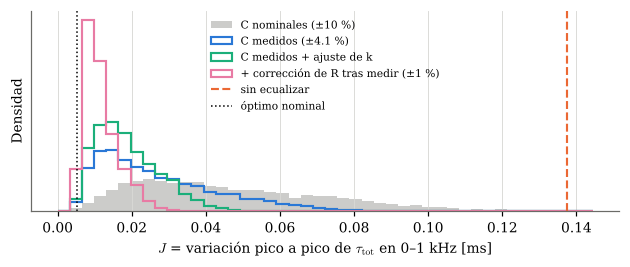

In [11]:
fig, ax = plt.subplots(figsize=(5.8, 2.5))
bins = np.linspace(0, 1e3 * J0 * 1.05, 45)
for (nombre, d), col in zip(ROB.items(), [GRIS, AZUL, VERDE, MAGENTA]):
    ax.hist(1e3 * d['J'], bins=bins, histtype='stepfilled' if col == GRIS else 'step', color=col, alpha=0.5 if col == GRIS else 1,
            lw=1.4, label=nombre, density=True)
ax.axvline(1e3 * J0, color=NARANJA, lw=1.4, ls='--', label='sin ecualizar')
ax.axvline(1e3 * J_OPT, color='k', lw=1, ls=':', label='óptimo nominal')
ax.set(xlabel=r'$J$ = variación pico a pico de $\tau_\mathrm{tot}$ en 0–1 kHz [ms]', ylabel='Densidad'); ax.set_yticks([])
ax.legend(fontsize=7)
fig.tight_layout(); guardar(fig, 'fig_ec_robustez'); plt.show()

## 6. Respuesta esperada
Retardo y magnitud del ecualizador con los componentes elegidos, retardo total con el filtro prototipo y respuesta al escalón de la cascada
(filtro + ecualizador) comparada con la del filtro solo.

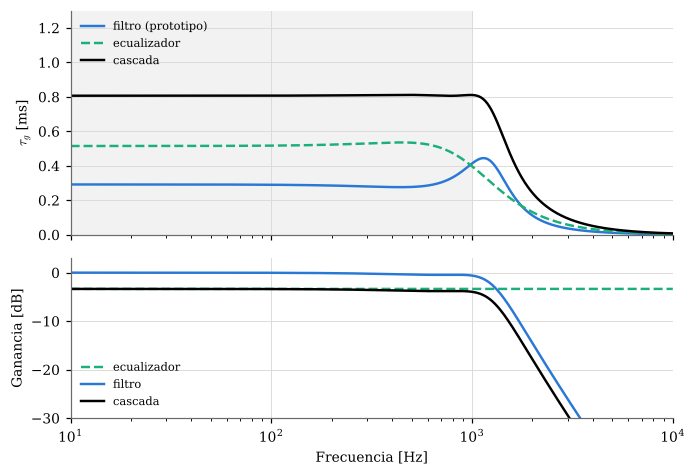

Ganancia del ecualizador: -3.35 dB; variación de |H_ec| en 10 Hz – 10 kHz: 2.22e-14 dB


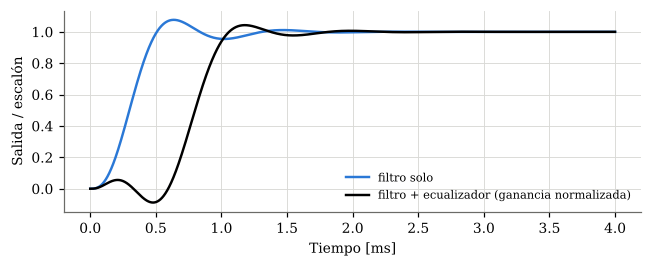

Sobrepico: filtro 7.66 %, cascada 4.27 % (pre-oscilación negativa de la cascada: 8.82 %)


In [12]:
ff = np.geomspace(10, 1e4, 3000)
Hf = lambda f: (2 * np.pi * PROTO[0]) / (2j * np.pi * f + 2 * np.pi * PROTO[0]) * (2 * np.pi * PROTO[1])**2 / (
    (2j * np.pi * f)**2 + (2 * np.pi * PROTO[1] / PROTO[2]) * 2j * np.pi * f + (2 * np.pi * PROTO[1])**2)
He = lambda f: H_ec(f, R1_C, R2_C, C1_D, C2_D, k_C)
fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.4), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
ax = axs[0]
ax.semilogx(ff, 1e3 * tau_filtro(ff, *PROTO), color=AZUL, label='filtro (prototipo)')
ax.semilogx(ff, 1e3 * tau_ec(ff, R1_C, R2_C, C1_D, C2_D, k_C), color=VERDE, ls='--', label='ecualizador')
ax.semilogx(ff, 1e3 * (tau_filtro(ff, *PROTO) + tau_ec(ff, R1_C, R2_C, C1_D, C2_D, k_C)), color='k', label='cascada')
ax.axvspan(10, FP, color=GRIS, alpha=0.12, lw=0); ax.set(ylabel=r'$\tau_g$ [ms]', ylim=(0, 1.3)); ax.legend(fontsize=7.5, loc='upper left')
ax = axs[1]
ax.semilogx(ff, 20 * np.log10(np.abs(He(ff))), color=VERDE, ls='--', label='ecualizador')
ax.semilogx(ff, 20 * np.log10(np.abs(Hf(ff))), color=AZUL, label='filtro')
ax.semilogx(ff, 20 * np.log10(np.abs(Hf(ff) * He(ff))), color='k', label='cascada')
ax.set(xlabel='Frecuencia [Hz]', ylabel='Ganancia [dB]', ylim=(-30, 3), xlim=(10, 1e4)); ax.legend(fontsize=7.5, loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_ec_respuesta'); plt.show()
print(f'Ganancia del ecualizador: {20*np.log10(k_C):.2f} dB; variación de |H_ec| en 10 Hz – 10 kHz: {np.ptp(20*np.log10(np.abs(He(ff)))):.2e} dB')

# Respuesta al escalón (modelo): filtro solo y cascada normalizada a ganancia 1
def tf_filtro(fr, f0, Q):
    wr, w0 = 2 * np.pi * fr, 2 * np.pi * f0
    return np.polymul([wr], [w0**2]), np.polymul([1, wr], [1, w0 / Q, w0**2])
nF_, dF_ = tf_filtro(*PROTO)
a1 = (C1_D + C2_D) / (R2_C * C1_D * C2_D); a0 = 1 / (R1_C * R2_C * C1_D * C2_D)
nE_, dE_ = [1, -a1, a0], [1, a1, a0]
t = np.linspace(0, 4e-3, 4000)
_, yF = signal.step((nF_, dF_), T=t)
_, yC = signal.step((np.polymul(nF_, nE_), np.polymul(dF_, dE_)), T=t)
fig, ax = plt.subplots(figsize=(6.0, 2.5))
ax.plot(1e3 * t, yF, color=AZUL, label='filtro solo')
ax.plot(1e3 * t, yC, color='k', label='filtro + ecualizador (ganancia normalizada)')
ax.set(xlabel='Tiempo [ms]', ylabel='Salida / escalón'); ax.legend(fontsize=7.5, loc='lower right')
fig.tight_layout(); guardar(fig, 'fig_ec_escalon_modelo'); plt.show()
SOB_F = 100 * (yF.max() - 1); SOB_C = 100 * (yC.max() - 1); PRE_C = -100 * yC[t < 1.5e-3].min()
print(f'Sobrepico: filtro {SOB_F:.2f} %, cascada {SOB_C:.2f} % (pre-oscilación negativa de la cascada: {PRE_C:.2f} %)')

## 7. Netlists de LTspice
* `ecualizador_ac.cir`: el ecualizador solo (AO: macromodelo de TI del TL072, que comparte etapa de entrada, GBW y slew rate con el TL081 del
  montaje), barrido AC.
* `filtro_ecualizado_ac.cir`: filtro (componentes nominales del prototipo) + ecualizador, barrido AC, nodos de salida 6 (filtro) y 9 (ecualizador).
* `filtro_ecualizado_escalon.cir`: lo mismo con un escalón de 1 V.

Nodos del ecualizador: 6 entrada (salida del filtro), 7 nodo A, 8 entrada inversora, 9 salida, 10 entrada no inversora; 71/81/101 uniones de
resistencias en serie; 102 cursor del preset. Se simula el montaje final (R medidas, C medidos) con el preset en la posición de magnitud plana.

In [13]:
def spice_val(x):
    for suf, fac in [('Meg', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('u', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= fac * 0.9999:
            return f'{x / fac:.6g}{suf}'
    return f'{x:.6g}'

def r_lineas(nombre, a, b, partes, medio):
    if len(partes) == 1:
        return [f'{nombre} {a} {b} {spice_val(partes[0])}']
    return [f'{nombre}a {a} {medio} {spice_val(partes[0])}', f'{nombre}b {medio} {b} {spice_val(partes[1])}']

def ecualizador(entrada='6', ao='tl072'):
    L = ['* Ecualizador pasatodo de 2.o orden (un AO): nodos 7 = A, 8 = entrada inversora, 9 = salida, 10 = entrada no inversora']
    L += r_lineas('R1e', entrada, '7', P_R1M, '71')
    L += [f'C1e 7 8 {spice_val(C1_D)}', f'C2e 7 9 {spice_val(C2_D)}']
    L += r_lineas('R2e', '8', '9', P_R2M, '81')
    L += [f'Ra {entrada} 10 {spice_val(RA_M)}']
    L += r_lineas('Rbf', '10', '102', (RBF_M,), '101')
    L += [f'Rpreset 102 0 {spice_val(RPRESET_M)}   ; preset en la posicion de magnitud plana (de 0 a {spice_val(PRESET)})']
    L += ['XU3 10 8 vcc vee 9 TL072' if ao == 'tl072' else 'E3 9 0 10 8 1e6']
    return L

# Filtro del prototipo: resistencias medidas y capacitores estimados a partir de su medición (notebook 04)
FP_COMP = {'R0': M04.get('mRceroMed', COMP['R0'] / 1e3) * 1e3, 'R1': M04.get('mRunoMed', COMP['R1'] / 1e3) * 1e3,
           'R2': M04.get('mRdosMed', COMP['R2'] / 1e3) * 1e3, 'C0': M04.get('mCceroEst', COMP['C0'] * 1e9) * 1e-9,
           'C1': M04.get('mCunoEst', COMP['C1'] * 1e9) * 1e-9, 'C2': M04.get('mCdosEst', COMP['C2'] * 1e9) * 1e-9}
def filtro_lineas():
    L = ['* Filtro del prototipo: R medidas y C estimados de su medicion (notebook 04); entrada en el nodo 1 (V6/V1, como el Bode)']
    L += [f'R0 1 2 {spice_val(FP_COMP["R0"])}', f'C0 2 0 {spice_val(FP_COMP["C0"])}',
          f'R1 3 4 {spice_val(FP_COMP["R1"])}', f'R2 4 5 {spice_val(FP_COMP["R2"])}',
          f'C1 4 6 {spice_val(FP_COMP["C1"])}', f'C2 5 0 {spice_val(FP_COMP["C2"])}',
          'XU1 2 3 vcc vee 3 TL072', 'XU2 5 6 vcc vee 6 TL072']
    return L
_wr = 1 / (FP_COMP['R0'] * FP_COMP['C0']); _w0 = 1 / np.sqrt(FP_COMP['R1'] * FP_COMP['R2'] * FP_COMP['C1'] * FP_COMP['C2'])
_Q = np.sqrt(FP_COMP['C1'] / FP_COMP['C2']) * np.sqrt(FP_COMP['R1'] * FP_COMP['R2']) / (FP_COMP['R1'] + FP_COMP['R2'])
print(f'Filtro del netlist (prototipo reconstruido): fr = {_wr/2/np.pi:.1f} Hz, f0 = {_w0/2/np.pi:.1f} Hz, Q = {_Q:.4f}  (ajuste: %.1f, %.1f, %.4f)' % PROTO)

CAB = ['* TP Integrador SRA 2026 - Grupo 3 - Nivel III: ecualizador de fase pasatodo',
       '* Generado por el notebook 06. AO: macromodelo TI TL072 (SLOJ067); el montaje usa un TL081 (misma familia)']
ALIM = ['.lib TL072.301', 'VCC vcc 0 12', 'VEE vee 0 -12']
NET = {
    'ecualizador_ac.cir': ['* Ecualizador solo - analisis AC'] + CAB + ['V1 6 0 AC 1'] + ecualizador() + ALIM + [
        '.ac dec 100 10 100k', '.meas AC Gbaja FIND mag(V(9)) AT 20', '.meas AC Gf0 FIND mag(V(9)) AT ' + f'{F0_AP:.1f}',
        '.meas AC Gmax MAX mag(V(9)) FROM 10 TO 10k', '.meas AC Gmin MIN mag(V(9)) FROM 10 TO 10k'],
    'filtro_ecualizado_ac.cir': ['* Filtro (prototipo) + ecualizador - analisis AC'] + CAB + ['V1 1 0 AC 1'] + filtro_lineas() + ecualizador() + ALIM + [
        '.ac dec 100 10 100k', '.save V(1) V(6) V(9)'],
    'filtro_ecualizado_escalon.cir': ['* Filtro (prototipo) + ecualizador - escalon de 1 V'] + CAB + ['V1 1 0 PULSE(0 1 1m 100n 100n 20m 40m)'] +
        filtro_lineas() + ecualizador() + ALIM + ['.tran 0 10m 0 1u', '.save V(1) V(6) V(9)', '.options plotwinsize=0'],
}
for nombre, L in NET.items():
    (LTS / nombre).write_text('\n'.join(L + ['.end']) + '\n', encoding='ascii')
print((LTS / 'ecualizador_ac.cir').read_text())

Filtro del netlist (prototipo reconstruido): fr = 786.4 Hz, f0 = 1241.0 Hz, Q = 1.4344  (ajuste: 786.4, 1241.0, 1.4344)
* Ecualizador solo - analisis AC
* TP Integrador SRA 2026 - Grupo 3 - Nivel III: ecualizador de fase pasatodo
* Generado por el notebook 06. AO: macromodelo TI TL072 (SLOJ067); el montaje usa un TL081 (misma familia)
V1 6 0 AC 1
* Ecualizador pasatodo de 2.o orden (un AO): nodos 7 = A, 8 = entrada inversora, 9 = salida, 10 = entrada no inversora
R1ea 6 71 4.673k
R1eb 71 7 118
C1e 7 8 47.33n
C2e 7 9 4.78n
R2ea 8 81 21.99k
R2eb 81 9 1.98k
Ra 6 10 9.92k
Rbf 10 102 19.92k
Rpreset 102 0 2.61922k   ; preset en la posicion de magnitud plana (de 0 a 10k)
XU3 10 8 vcc vee 9 TL072
.lib TL072.301
VCC vcc 0 12
VEE vee 0 -12
.ac dec 100 10 100k
.meas AC Gbaja FIND mag(V(9)) AT 20
.meas AC Gf0 FIND mag(V(9)) AT 991.5
.meas AC Gmax MAX mag(V(9)) FROM 10 TO 10k
.meas AC Gmin MIN mag(V(9)) FROM 10 TO 10k
.end



### 7.1 Verificación con el solver nodal
El ecualizador del netlist (con el AO reemplazado por una fuente controlada de ganancia $10^6$) se resuelve con un solver MNA y se compara con la
transferencia simbólica con los mismos valores (y $k$ del divisor con el preset a mitad de recorrido).

In [14]:
def mna(lineas, f, salida, fuente='V1'):
    els = []
    for l in lineas:
        t = l.split(';')[0].split()
        if not t or t[0].startswith(('*', '.')) or t[0].startswith('X'):
            continue
        els.append(t)
    sfx = {'meg': 1e6, 'k': 1e3, 'm': 1e-3, 'u': 1e-6, 'n': 1e-9, 'p': 1e-12}
    def val(x):
        m = re.fullmatch(r'([\d.eE+-]+)(meg|k|m|u|n|p)?', x.lower()); return float(m.group(1)) * sfx.get(m.group(2), 1.0)
    nodos = sorted({n for e in els for n in (e[1:5] if e[0][0] == 'E' else e[1:3]) if n != '0'})
    idx = {n: i for i, n in enumerate(nodos)}; ext = [e for e in els if e[0][0] in 'VE']
    out = []
    for fk in f:
        sk = 2j * np.pi * fk; N_ = len(nodos)
        A = np.zeros((N_ + len(ext),) * 2, complex); b = np.zeros(N_ + len(ext), complex)
        def est(a, c, y):
            for p_, q_, sg in [(a, a, 1), (c, c, 1), (a, c, -1), (c, a, -1)]:
                if p_ != '0' and q_ != '0':
                    A[idx[p_], idx[q_]] += sg * y
        j = 0
        for e in els:
            if e[0][0] == 'R':
                est(e[1], e[2], 1 / val(e[3]))
            elif e[0][0] == 'C':
                est(e[1], e[2], sk * val(e[3]))
            else:
                fila = N_ + j; j += 1
                for n_, sg in [(e[1], 1), (e[2], -1)]:
                    if n_ != '0':
                        A[idx[n_], fila] += sg; A[fila, idx[n_]] += sg
                if e[0][0] == 'V':
                    b[fila] = 1.0
                else:
                    g = float(e[5])
                    for n_, sg in [(e[3], 1), (e[4], -1)]:
                        if n_ != '0':
                            A[fila, idx[n_]] -= sg * g
        out.append(np.linalg.solve(A, b)[idx[salida]])
    return np.array(out)

fv = np.geomspace(10, 1e5, 300)
lin_ideal = ['V1 6 0 AC 1'] + ecualizador(ao='ideal')
k_div = (RBF_M + RPRESET_M) / (RA_M + RBF_M + RPRESET_M)
ERR_NET = np.max(np.abs(mna(lin_ideal, fv, '9') / H_ec(fv, R1_M, R2_M, C1_D, C2_D, k_div) - 1))
print(f'Netlist del ecualizador vs transferencia simbólica: error relativo máximo = {ERR_NET:.1e} (k del divisor = {k_div:.4f})')

Netlist del ecualizador vs transferencia simbólica: error relativo máximo = 5.2e-06 (k del divisor = 0.6944)


### 7.2 Resultados de LTspice
Se leen los `.raw`/`.log` de `ltspice/resultados/` cuando estén disponibles.

Disponibles: {'ecualizador_ac': True, 'filtro_ecualizado_ac': True, 'escalon': True}
{'ec_rizado_dB': np.float64(0.021134101970201158), 'ec_ganancia_dB': np.float64(-3.168251640409828), 'ec_tau_err_max_us': np.float64(0.35682787904252244), 'J_filtro_ms': np.float64(0.1379259777639487), 'J_cascada_ms': np.float64(0.0346752715887598)}


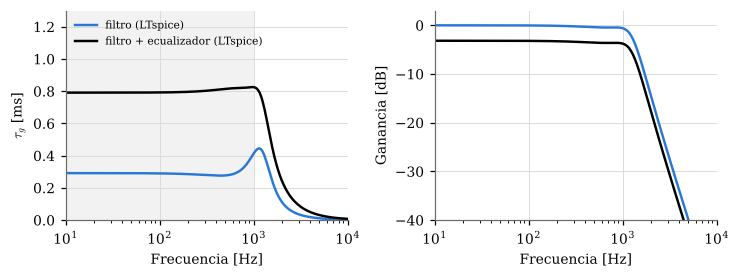

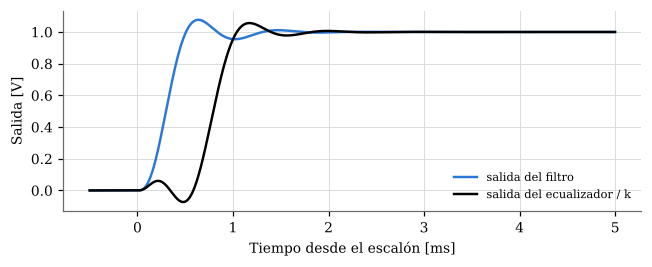

{'esc_sob_f_pct': np.float32(7.68), 'esc_sob_e_pct': np.float32(5.63), 'esc_pre_e_pct': np.float32(7.31)}


In [15]:
try:
    from spicelib import RawRead
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'spicelib'], check=True)
    from spicelib import RawRead

def leer_raw(nombre, trazas):
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            raw = RawRead(str(p))
            eje = 'frequency' if 'frequency' in [t.lower() for t in raw.get_trace_names()] else 'time'
            x = raw.get_trace(eje).get_wave()
            try:
                return np.abs(x) if eje == 'frequency' else np.real(x), {t: raw.get_trace(t).get_wave() for t in trazas}
            except IndexError:
                print(f'{nombre}: faltan trazas {trazas} -> resultado de un netlist anterior, se descarta')
                return None
    return None

LT_EC = leer_raw('ecualizador_ac.raw', ['V(9)'])
LT_CAS = leer_raw('filtro_ecualizado_ac.raw', ['V(6)', 'V(9)'])
LT_ESC = leer_raw('filtro_ecualizado_escalon.raw', ['V(1)', 'V(6)', 'V(9)'])
print('Disponibles:', {k: v is not None for k, v in {'ecualizador_ac': LT_EC, 'filtro_ecualizado_ac': LT_CAS, 'escalon': LT_ESC}.items()})

def tau_de_fase(f, H, paso=1):
    ph = np.unwrap(np.angle(H)); w = 2 * np.pi * f
    return np.sqrt(f[paso:] * f[:-paso]), -(ph[paso:] - ph[:-paso]) / (w[paso:] - w[:-paso])

# Control: los resultados deben corresponder a los netlists actuales (la ganancia del ecualizador debe ser k del divisor)
if LT_EC is not None:
    g20 = 20 * np.log10(np.abs(np.interp(20, LT_EC[0], np.abs(LT_EC[1]['V(9)']))))
    if abs(g20 - 20 * np.log10(k_div)) > 0.05:
        print(f'ATENCIÓN: ganancia de LTspice {g20:.3f} dB distinta de 20 log k = {20*np.log10(k_div):.3f} dB -> resultados de un netlist anterior; '
              'se descartan (volver a correr los .cir)')
        LT_EC = LT_CAS = LT_ESC = None
RES_LT = {}
if LT_EC is not None:
    f_, d_ = LT_EC; h_ = d_['V(9)']
    g = 20 * np.log10(np.abs(h_)); RES_LT['ec_rizado_dB'] = np.ptp(g[(f_ >= 10) & (f_ <= 1e4)]); RES_LT['ec_ganancia_dB'] = g[np.argmin(np.abs(f_ - 20))]
    fm_, tm_ = tau_de_fase(f_, h_)
    RES_LT['ec_tau_err_max_us'] = 1e6 * np.max(np.abs(np.interp(F_B, fm_, tm_) - tau_ec(F_B, R1_M, R2_M, C1_D, C2_D, k_div)))
    if RES_LT['ec_tau_err_max_us'] > 10:
        print(f"ATENCIÓN: el retardo de LTspice difiere {RES_LT['ec_tau_err_max_us']:.1f} µs del calculado para el netlist actual -> "
              'resultados de un netlist anterior; se descartan (volver a correr los .cir)')
        LT_EC = LT_CAS = LT_ESC = None; RES_LT = {}
if LT_CAS is not None:
    f_, d_ = LT_CAS
    for nodo, clave in (('V(6)', 'filtro'), ('V(9)', 'cascada')):
        fm_, tm_ = tau_de_fase(f_, d_[nodo]); tb = np.interp(F_B, fm_, tm_)
        RES_LT[f'J_{clave}_ms'] = 1e3 * J_pp(tb)
print(RES_LT)

if LT_CAS is not None:
    f_, d_ = LT_CAS
    fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.6))
    for nodo, col, et in (('V(6)', AZUL, 'filtro (LTspice)'), ('V(9)', 'k', 'filtro + ecualizador (LTspice)')):
        fm_, tm_ = tau_de_fase(f_, d_[nodo])
        axs[0].semilogx(fm_, 1e3 * tm_, color=col, label=et)
        axs[1].semilogx(f_, 20 * np.log10(np.abs(d_[nodo])), color=col, label=et)
    axs[0].axvspan(10, FP, color=GRIS, alpha=0.12, lw=0)
    axs[0].set(xlim=(10, 1e4), ylim=(0, 1.3), xlabel='Frecuencia [Hz]', ylabel=r'$\tau_g$ [ms]'); axs[0].legend(fontsize=7, loc='upper left')
    axs[1].set(xlim=(10, 1e4), ylim=(-40, 3), xlabel='Frecuencia [Hz]', ylabel='Ganancia [dB]')
    fig.tight_layout(); guardar(fig, 'fig_ec_ltspice'); plt.show()
if LT_ESC is not None:
    t_, d_ = LT_ESC
    fig, ax = plt.subplots(figsize=(6.0, 2.5))
    m_ = (t_ >= 0.5e-3) & (t_ <= 6e-3)
    ax.plot(1e3 * (t_[m_] - 1e-3), np.real(d_['V(6)'][m_]), color=AZUL, label='salida del filtro')
    ax.plot(1e3 * (t_[m_] - 1e-3), np.real(d_['V(9)'][m_]) / k_div, color='k', label='salida del ecualizador / k')
    ax.set(xlabel='Tiempo desde el escalón [ms]', ylabel='Salida [V]'); ax.legend(fontsize=7.5, loc='lower right')
    fig.tight_layout(); guardar(fig, 'fig_ec_ltspice_escalon'); plt.show()
    yf_ = np.real(d_['V(6)']); ye_ = np.real(d_['V(9)']) / k_div; ta_ = t_ - 1e-3
    RES_LT['esc_sob_f_pct'] = 100 * (yf_[ta_ > 0].max() / yf_[-1] - 1); RES_LT['esc_sob_e_pct'] = 100 * (ye_[ta_ > 0.8e-3].max() / ye_[-1] - 1)
    RES_LT['esc_pre_e_pct'] = 100 * max(0.0, -ye_[(ta_ > 0) & (ta_ < 0.8e-3)].min() / ye_[-1])
    print({k: round(v, 2) for k, v in RES_LT.items() if k.startswith('esc')})

## 8. Medición
Archivos de `mediciones/nivel3/` (exportados por el Bode del Rigol, sin modificar; puntas ×10):
* `bode_calibracion.csv`: CH1 y CH2 en el mismo punto; es el error del instrumento entre canales y se descuenta de todas las mediciones.
* `bode_filtro.csv`, `bode_ecualizador.csv`, `bode_cascada.csv`, `escalon_cascada.csv`: filtro solo, ecualizador solo y cascada, con el
  ecualizador ya sintonizado. Las mediciones intermedias de la sintonía están en `mediciones/nivel3/sintonia/`.

**Sintonía.** Los capacitores solo se conocen con la exactitud del UT61D+ (±4 %), así que el ecualizador armado se apartó del objetivo. Se sintonizó
midiendo su respuesta, calculando los capacitores "efectivos" que explican el $f_0$ y el $Q$ medidos y cambiando la resistencia menor de cada par
por el valor E24 que lo lleva al óptimo (dos iteraciones); el preset se reajustó después de cada cambio.

In [16]:
def leer_bode_rigol(p):
    """Lee el CSV del modo Bode del Rigol MSO5000 (frecuencia, ganancia en dB, fase en grados)."""
    if not p.exists():
        return None
    filas_ = []
    for l in p.read_text(encoding='utf-8', errors='ignore').splitlines():
        partes = [x.strip() for x in l.replace(';', ',').split(',')]
        try:
            vals = [float(x) for x in partes if x != '']
        except ValueError:
            continue
        if len(vals) >= 3:
            filas_.append(vals[-3:])
    d = pd.DataFrame(filas_, columns=['f', 'G', 'F'])
    return d[d['f'] > 0].sort_values('f').reset_index(drop=True)

def sin_arranque(B, n_max=5, tol_dB=0.3):
    """Descarta los primeros puntos del barrido mientras difieran de la ganancia típica de los siguientes (transitorio de arranque del Bode)."""
    if B is None:
        return None
    ref = np.median(B['G'].values[n_max:n_max + 8]); i = 0
    while i < n_max and abs(B['G'].values[i] - ref) > tol_dB:
        i += 1
    return B.iloc[i:].reset_index(drop=True)

B_CAL = leer_bode_rigol(MED3 / 'bode_calibracion.csv')
if B_CAL is not None:
    arranque = (np.arange(len(B_CAL)) < 5) & ((B_CAL['G'].abs() > 0.5) | (((B_CAL['F'] + 180) % 360 - 180).abs() > 5))
    B_CAL = B_CAL[~arranque].reset_index(drop=True)
    m_ = B_CAL['f'] <= 2e4
    CAL_MAX = (B_CAL['G'][m_].abs().max(), ((B_CAL['F'][m_] + 180) % 360 - 180).abs().max())
    print(f'Calibración de canales: error ≤ {CAL_MAX[0]:.3f} dB y ≤ {CAL_MAX[1]:.2f}° hasta 20 kHz; se descuenta')

def cargar(nombre):
    B = sin_arranque(leer_bode_rigol(MED3 / nombre))
    if B is None or B_CAL is None:
        return B
    B = B.copy()
    B['G'] = B['G'] - np.interp(np.log10(B['f']), np.log10(B_CAL['f']), B_CAL['G'])
    B['F'] = B['F'] - np.interp(np.log10(B['f']), np.log10(B_CAL['f']), (B_CAL['F'] + 180) % 360 - 180)
    return B

BOD = {k_: cargar(f'{k_}.csv') for k_ in ('bode_filtro', 'bode_ecualizador', 'bode_cascada')}
print('Disponibles:', {k_: v is not None for k_, v in BOD.items()})
U_G, U_F = 0.213, 1.0
CORTE_dB = 30.0      # mismo criterio que el notebook 04: se ajustan los puntos con la salida a no más de 30 dB por debajo de la de continua

def desenrollar(f, F, H_ref):
    ref = np.degrees(np.unwrap(np.angle(H_ref(f))))
    return F + 360 * np.round((ref - F) / 360)

def H_ap_mod(f, f0, Q, k, eps):
    sj = 2j * np.pi * np.asarray(f, float); w0 = 2 * np.pi * f0
    return k * (sj**2 - (1 - eps) * w0 / Q * sj + w0**2) / (sj**2 + w0 / Q * sj + w0**2)

def H_lp_mod(f, fr, f0, Q, K=1.0):
    sj = 2j * np.pi * np.asarray(f, float); wr, w0 = 2 * np.pi * fr, 2 * np.pi * f0
    return K * wr / (sj + wr) * w0**2 / (sj**2 + w0 / Q * sj + w0**2)

def tau_ap_eps(f, f0, Q, eps):
    w0 = 2 * np.pi * f0; a1 = w0 / Q
    return tau_raices(list(np.roots([1, a1, w0**2])), list(np.roots([1, -(1 - eps) * a1, w0**2])), f)

def ajustar_bode(f, G, F, modelo, p0, escala):
    def res(p):
        Hm = modelo(f, *p)
        return np.concatenate([(G - 20 * np.log10(np.abs(Hm))) / U_G, (F - np.degrees(np.unwrap(np.angle(Hm)))) / U_F])
    r = optimize.least_squares(res, p0, x_scale=escala)
    c2 = np.sum(r.fun**2) / max(1, len(r.fun) - len(p0))
    cov = np.linalg.pinv(r.jac.T @ r.jac) * max(1.0, c2)
    return r.x, np.sqrt(np.diag(cov)), cov

def ajuste_ecualizador(B, p0=(F0_AP, Q_AP, k_C, 0.0)):
    f, G = B['f'].values, B['G'].values
    F = desenrollar(f, B['F'].values, lambda x: H_ap_mod(x, p0[0], p0[1], p0[2], 0.0))
    m = f <= 2e4
    return ajustar_bode(f[m], G[m], F[m], H_ap_mod, list(p0), [50, 0.05, 0.05, 0.01])

def ajuste_filtro(B, p0=PROTO):
    f, G = B['f'].values, B['G'].values
    F = desenrollar(f, B['F'].values, lambda x: H_lp_mod(x, *p0))
    G0 = np.mean(G[f <= 30]); m = G >= G0 - CORTE_dB
    return ajustar_bode(f[m], G[m], F[m], H_lp_mod, list(p0) + [1.0], [50, 50, 0.1, 0.05])

def capacitores_efectivos(f0, Q, R1, R2):
    """C1, C2 que, con las resistencias montadas, dan el f0 y Q medidos del ecualizador."""
    w0 = 2 * np.pi * f0; prod = 1 / (w0**2 * R1 * R2); suma = np.sqrt(R2 / R1) * np.sqrt(prod) / Q
    d = np.sqrt(suma**2 - 4 * prod); return (suma + d) / 2, (suma - d) / 2

RM = META3.get('resistencias_medidas_ohm', {}) or {}
E24a = np.asarray(E24_R)
def desvio_lineal(f, F):
    """Desvío de la fase respecto de la recta que mejor la aproxima (fase lineal = retardo constante) [°] y retardo de esa recta [s]."""
    w = 2 * np.pi * f; A = np.vstack([w, np.ones_like(w)]).T
    c, *_ = np.linalg.lstsq(A, F, rcond=None)
    return F - A @ c, -np.radians(c[0])

def tau_local(f, F, media_decada=0.08):
    """Retardo por regresión cuadrática local de la fase en función de ω (ventana de ±media_decada)."""
    w = 2 * np.pi * f; Fr = np.radians(F); out = np.full(len(f), np.nan)
    for i, fi in enumerate(f):
        m = np.abs(np.log10(f / fi)) <= media_decada
        if m.sum() >= 5:
            out[i] = -np.polyfit(w[m] - w[i], Fr[m], 2)[1]
    return out

# Estado final
MED_RES = {}
if all(BOD[k_] is not None for k_ in ('bode_filtro', 'bode_ecualizador', 'bode_cascada')):
    pF, uF_, _ = ajuste_filtro(BOD['bode_filtro'], p0=PROTO)
    pE, uE, _ = ajuste_ecualizador(BOD['bode_ecualizador'], p0=(F0_AP, Q_AP, k_C, 0.0))
    tau_Ff = tau_filtro(F_B, *pF[:3]); J_fil = J_pp(tau_Ff)
    J_pred = J_pp(tau_Ff + tau_ap_eps(F_B, pE[0], pE[1], pE[3]))
    # Cascada: filtro fijo (ajuste de la medición del filtro solo), ecualizador libre
    Bc = BOD['bode_cascada']; fc, Gc = Bc['f'].values, Bc['G'].values
    Fc = desenrollar(fc, Bc['F'].values, lambda x: H_lp_mod(x, *pF) * H_ap_mod(x, *pE))
    mc = Gc >= np.mean(Gc[fc <= 30]) - CORTE_dB
    mod_c = lambda f, f0a, Qa, eps, K: H_lp_mod(f, *pF[:3], K) * H_ap_mod(f, f0a, Qa, 1.0, eps)
    pC, uC, covC = ajustar_bode(fc[mc], Gc[mc], Fc[mc], mod_c, [pE[0], pE[1], pE[3], pF[3] * pE[2]], [50, 0.05, 0.01, 0.05])
    J_cas = J_pp(tau_Ff + tau_ap_eps(F_B, pC[0], pC[1], pC[2]))
    # incertidumbre de J: parámetros del filtro y de la cascada
    rngJ = np.random.default_rng(7)
    qF = rngJ.normal(pF[:3], uF_[:3], (2000, 3)); qC = rngJ.multivariate_normal(pC, covC, 2000)
    Js = np.array([J_pp(tau_filtro(F_B, *a) + tau_ap_eps(F_B, b[0], b[1], b[2])) for a, b in zip(qF, qC)])
    J0s = np.array([J_pp(tau_filtro(F_B, *a)) for a in qF])
    # Consistencia: cascada medida vs filtro medido + ecualizador medido (fase); los puntos que no cumplen son artefactos del instrumento
    Bf, Be = BOD['bode_filtro'], BOD['bode_ecualizador']
    Ff_u = desenrollar(Bf['f'].values, Bf['F'].values, lambda x: H_lp_mod(x, *pF))
    Fe_u = desenrollar(Be['f'].values, Be['F'].values, lambda x: H_ap_mod(x, *pE))
    suma = np.interp(np.log(fc), np.log(Bf['f']), Ff_u) + np.interp(np.log(fc), np.log(Be['f']), Fe_u)
    inc = (Fc - suma + 180) % 360 - 180
    banda = (fc >= 20) & (fc <= FP)
    artef = banda & (np.abs(inc) > 2.0)
    # Métrica sin modelo: desvío de la fase respecto de la mejor recta en 20 Hz – 1 kHz, excluyendo esos puntos (en ambas mediciones)
    ff_, Gf_ = Bf['f'].values, Bf['G'].values
    bf = (ff_ >= 20) & (ff_ <= FP) & ~np.isin(np.round(ff_, 2), np.round(fc[artef], 2))
    bc = banda & ~artef
    dev_f, t0_f = desvio_lineal(ff_[bf], Ff_u[bf]); dev_c, t0_c = desvio_lineal(fc[bc], Fc[bc])
    MED_RES = {'fil_fr': pF[0], 'fil_f0': pF[1], 'fil_Q': pF[2], 'fil_ufr': uF_[0], 'fil_uf0': uF_[1], 'fil_uQ': uF_[2],
               'ap_f0': pE[0], 'ap_uf0': uE[0], 'ap_Q': pE[1], 'ap_uQ': uE[1], 'ap_k': pE[2], 'ap_eps': pE[3], 'ap_ueps': uE[3],
               'ap_valle_dB': 20 * np.log10(abs(1 - pE[3])),
               'cas_f0': pC[0], 'cas_Q': pC[1], 'cas_eps': pC[2], 'cas_K': pC[3],
               'J_fil': J_fil, 'J_pred': J_pred, 'J_cas': J_cas, 'u_J_cas': Js.std(), 'u_J_fil': J0s.std(),
               'mejora': J_fil / J_cas, 'mejora_p05': np.percentile(J0s / Js, 5), 'mejora_p95': np.percentile(J0s / Js, 95),
               'inc_mediana': np.median(np.abs(inc[banda])), 'n_artef': int(artef.sum()),
               'fil_dev_max': np.abs(dev_f).max(), 'fil_dev_rms': dev_f.std(), 'cas_dev_max': np.abs(dev_c).max(), 'cas_dev_rms': dev_c.std(),
               'fil_tau_lin': t0_f, 'cas_tau_lin': t0_c,
               'cas_G_rizado': np.ptp(Gc[(fc >= 20) & (fc <= FP)]) , 'ap_rizado_dB': np.ptp(signal.medfilt(Be['G'].values, 5)[Be['f'].values <= 1e4])}
    print(pd.Series({k_: (round(v, 5) if isinstance(v, float) else v) for k_, v in MED_RES.items()}).to_string())
    print('Artefactos excluidos de la métrica de fase:', np.round(fc[artef], 0), np.round(inc[artef], 1))
pd.Series(MED_RES, dtype=object)

Calibración de canales: error ≤ 0.020 dB y ≤ 0.41° hasta 20 kHz; se descuenta
Disponibles: {'bode_filtro': True, 'bode_ecualizador': True, 'bode_cascada': True}


fil_fr           786.40797
fil_f0          1241.03888
fil_Q              1.43436
fil_ufr            6.37443
fil_uf0            3.02477
fil_uQ             0.00885
ap_f0            981.42129
ap_uf0             1.19648
ap_Q               0.62575
ap_uQ              0.00246
ap_k               0.69336
ap_eps             0.02249
ap_ueps            0.00607
ap_valle_dB       -0.19761
cas_f0           985.47657
cas_Q              0.62253
cas_eps            0.01768
cas_K              0.69032
J_fil              0.00014
J_pred             0.00001
J_cas              0.00001
u_J_cas            0.00000
u_J_fil            0.00000
mejora            16.59641
mejora_p05        10.16463
mejora_p95        21.61376
inc_mediana        0.09000
n_artef            2.00000
fil_dev_max        6.59209
fil_dev_rms        1.07254
cas_dev_max        1.49285
cas_dev_rms        0.40193
fil_tau_lin        0.00029
cas_tau_lin        0.00081
cas_G_rizado       0.90000
ap_rizado_dB       0.41000
Artefactos excluidos de la m

fil_fr           786.407967
fil_f0          1241.038879
fil_Q              1.434363
fil_ufr            6.374431
fil_uf0            3.024768
fil_uQ             0.008849
ap_f0            981.421291
ap_uf0             1.196479
ap_Q               0.625746
ap_uQ              0.002457
ap_k                0.69336
ap_eps             0.022494
ap_ueps            0.006075
ap_valle_dB       -0.197612
cas_f0           985.476571
cas_Q              0.622532
cas_eps            0.017681
cas_K               0.69032
J_fil              0.000137
J_pred             0.000013
J_cas              0.000008
u_J_cas            0.000002
u_J_fil            0.000002
mejora            16.596409
mejora_p05        10.164626
mejora_p95        21.613758
inc_mediana            0.09
n_artef                   2
fil_dev_max        6.592095
fil_dev_rms        1.072542
cas_dev_max        1.492848
cas_dev_rms         0.40193
fil_tau_lin        0.000291
cas_tau_lin        0.000813
cas_G_rizado            0.9
ap_rizado_dB        

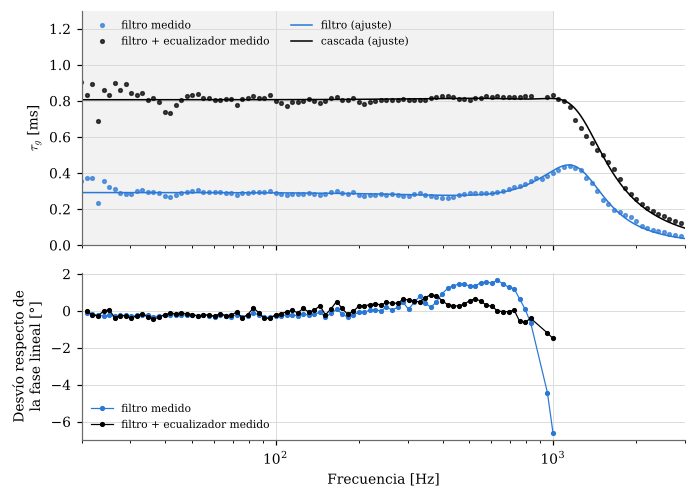

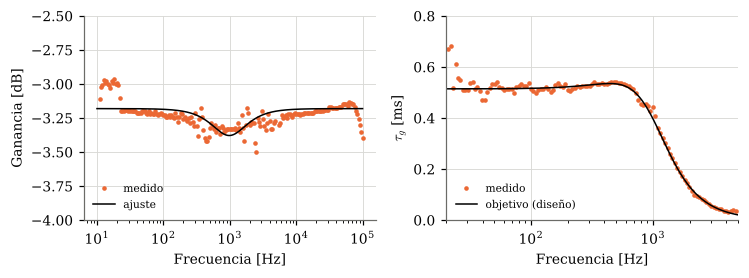

In [17]:
if MED_RES:
    fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.6), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
    ax = axs[0]; ft_ = np.geomspace(10, 3000, 1500)
    for B, col, et, modelo in [(Bf, AZUL, 'filtro medido', lambda x: H_lp_mod(x, *pF)), (Bc, 'k', 'filtro + ecualizador medido', None)]:
        f_ = B['f'].values
        F_ = Ff_u if B is Bf else Fc
        ok = np.ones(len(f_), bool) if B is Bf else ~artef
        t_ = tau_local(f_[ok], F_[ok]); sel = f_[ok] <= 3000
        ax.semilogx(f_[ok][sel], 1e3 * t_[sel], 'o', ms=2.4, color=col, alpha=0.7, label=et)
    ax.semilogx(ft_, 1e3 * tau_filtro(ft_, *pF[:3]), color=AZUL, lw=1, label='filtro (ajuste)')
    ax.semilogx(ft_, 1e3 * (tau_filtro(ft_, *pF[:3]) + tau_ap_eps(ft_, pC[0], pC[1], pC[2])), color='k', lw=1, label='cascada (ajuste)')
    ax.axvspan(10, FP, color=GRIS, alpha=0.12, lw=0); ax.set(ylabel=r'$\tau_g$ [ms]', ylim=(0, 1.3)); ax.legend(fontsize=7, loc='upper left', ncol=2)
    ax = axs[1]
    ax.semilogx(ff_[bf], dev_f, 'o-', ms=2.4, lw=0.8, color=AZUL, label='filtro medido')
    ax.semilogx(fc[bc], dev_c, 'o-', ms=2.4, lw=0.8, color='k', label='filtro + ecualizador medido')
    ax.set(xlabel='Frecuencia [Hz]', ylabel='Desvío respecto de\nla fase lineal [°]', xlim=(20, 3000)); ax.legend(fontsize=7)
    fig.tight_layout(); guardar(fig, 'fig_ec_medicion'); plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.6))
    ft_ = np.geomspace(10, 1e5, 1500)
    B = BOD['bode_ecualizador']
    axs[0].semilogx(B['f'], B['G'], 'o', ms=2, color=NARANJA, label='medido')
    axs[0].semilogx(ft_, 20 * np.log10(np.abs(H_ap_mod(ft_, *pE))), color='k', lw=1, label='ajuste')
    Fu = desenrollar(B['f'].values, B['F'].values, lambda x: H_ap_mod(x, *pE))
    t_ = tau_local(B['f'].values, Fu); sel = (B['f'].values <= 5000) & (B['f'].values >= 20)
    axs[1].semilogx(B['f'].values[sel], 1e3 * t_[sel], 'o', ms=2, color=NARANJA, label='medido')
    axs[1].semilogx(ft_, 1e3 * tau_ap2(ft_, F0_AP, Q_AP), color='k', lw=1, label='objetivo (diseño)')
    axs[0].set(xlabel='Frecuencia [Hz]', ylabel='Ganancia [dB]', ylim=(-4, -2.5)); axs[0].legend(fontsize=7, loc='lower left')
    axs[1].set(xlabel='Frecuencia [Hz]', ylabel=r'$\tau_g$ [ms]', xlim=(20, 5000), ylim=(0, 0.8)); axs[1].legend(fontsize=7, loc='lower left')
    fig.tight_layout(); guardar(fig, 'fig_ec_medicion_ap'); plt.show()

### Sintonía: las tres mediciones del ecualizador solo
Montaje inicial, primera corrección y estado final (archivos en `mediciones/nivel3/sintonia/` y `mediciones/nivel3/`). En cada paso se ajusta
$f_0$, $Q$, $k$ y $\varepsilon$ y se calcula el $J$ que daría con el filtro medido. Las correcciones cambian sólo la resistencia menor de cada par.

In [18]:
SINT = []
if MED_RES:
    _RC1 = RM.get('primera_correccion', {}) or {}
    pasos = [('Montaje inicial', 'sintonia/bode_ecualizador_antes_correccion.csv', P_R1I, P_R2I),
             ('Primera corrección', 'sintonia/bode_ecualizador_v2.csv', tuple(_RC1.get('R1e_partes') or ()), tuple(_RC1.get('R2e_partes') or ())),
             ('Final', 'bode_ecualizador.csv', P_R1M, P_R2M)]
    for nom_, arch_, pr1, pr2 in pasos:
        if not (MED3 / arch_).exists() or not pr1:
            continue
        p_, u_, _ = ajuste_ecualizador(cargar(arch_), p0=(F0_AP, Q_AP, k_C, 0.0))
        Jp_ = J_pp(tau_filtro(F_B, *pF[:3]) + tau_ap_eps(F_B, p_[0], p_[1], p_[3]))
        SINT.append(dict(paso=nom_, R1=pr1, R2=pr2, f0=p_[0], uf0=u_[0], Q=p_[1], uQ=u_[1], J=Jp_))
        print(f'{nom_:20s}: R1 = {sum(pr1):.0f} Ω, R2 = {sum(pr2):.0f} Ω -> f0 = {p_[0]:.1f} ± {u_[0]:.1f} Hz, Q = {p_[1]:.4f} ± {u_[1]:.4f}, '
              f'J (con el filtro medido) = {1e3*Jp_:.4f} ms (mejora × {J_fil/Jp_:.1f})')
    print(f'Objetivo: f0 = {F0_AP:.1f} Hz, Q = {Q_AP:.4f}')

Montaje inicial     : R1 = 4994 Ω, R2 = 25268 Ω -> f0 = 947.3 ± 1.2 Hz, Q = 0.6290 ± 0.0025, J (con el filtro medido) = 0.0299 ms (mejora × 4.6)
Primera corrección  : R1 = 4891 Ω, R2 = 25786 Ω -> f0 = 936.9 ± 1.1 Hz, Q = 0.6416 ± 0.0025, J (con el filtro medido) = 0.0274 ms (mejora × 5.0)
Final               : R1 = 4791 Ω, R2 = 23970 Ω -> f0 = 981.4 ± 1.2 Hz, Q = 0.6257 ± 0.0025, J (con el filtro medido) = 0.0127 ms (mejora × 10.8)
Objetivo: f0 = 991.5 Hz, Q = 0.6244


### 8.1 Respuesta a la onda cuadrada
`escalon_cascada.csv` (estado final): CH1 entrada, CH2 salida del filtro, CH3 salida del ecualizador. Cada salida se normaliza por su propio salto
(la del ecualizador tiene ganancia $k$) y se miden sobrepico, pre-oscilación (excursión negativa antes de la subida), tiempo de subida 10–90 % y
retardo al 50 %.

{'vf': {'sobrepico': np.float64(7.880395), 'preoscilacion': 0.0, 't10': np.float64(0.000148), 't50': np.float64(0.000303), 't90': np.float64(0.000454), 'u_pct': np.float64(1.255103)}, 've': {'sobrepico': np.float64(3.125008), 'preoscilacion': np.float64(6.375001), 't10': np.float64(0.00065), 't50': np.float64(0.000815), 't90': np.float64(0.000991), 'u_pct': np.float64(1.804216)}}


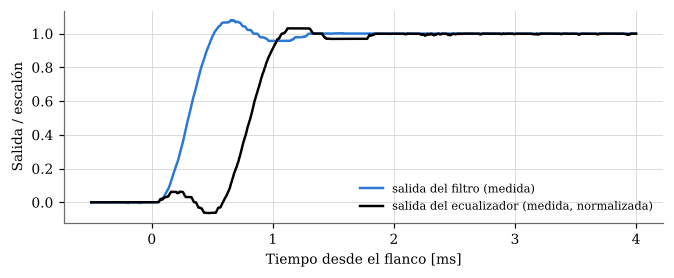

In [19]:
ESC_MED = {}
arch_esc = next((p_ for p_ in (MED3 / 'escalon_cascada.csv',) if p_.exists()), None)
if arch_esc is not None:
    e = pd.read_csv(arch_esc).iloc[:, :4]; e.columns = ['t', 'vi', 'vf', 've']
    t_ = e['t'].to_numpy(float); vi_ = e['vi'].to_numpy(float)
    vi0, vi1 = np.median(vi_[vi_ < vi_.mean()]), np.median(vi_[vi_ > vi_.mean()])
    sube = np.where((vi_[:-1] < (vi0 + vi1) / 2) & (vi_[1:] >= (vi0 + vi1) / 2))[0]
    t0 = t_[sube[0] + 1]; tt = t_ - t0
    paso_t = np.median(np.diff(t_)); nmed = max(int(round(20e-6 / paso_t)), 1)
    for canal in ('vf', 've'):
        v = np.convolve(e[canal].to_numpy(float), np.ones(nmed) / nmed, mode='same')
        v0 = np.median(v[(tt < -0.2e-3) & (tt > -2e-3)]); v1 = np.median(v[(tt > 2.5e-3) & (tt < 4e-3)])
        y = (v - v0) / (v1 - v0)
        ventana = (tt > -0.5e-3) & (tt < 4e-3)
        lsb = float(np.min(np.diff(np.unique(np.round(e[canal].to_numpy(float), 9)))))
        ESC_MED[canal] = {'sobrepico': 100 * (y[ventana & (tt > 0)].max() - 1),
                          'preoscilacion': 100 * max(0.0, -y[(tt > 0) & (tt < 1e-3)].min()),
                          't10': tt[ventana & (y >= 0.1)][0], 't50': tt[ventana & (y >= 0.5)][0], 't90': tt[ventana & (y >= 0.9)][0],
                          'u_pct': 100 * lsb / (np.sqrt(3) * abs(v1 - v0)), 'y': y}
    print({c: {k_: round(v_, 6) for k_, v_ in d.items() if k_ != 'y'} for c, d in ESC_MED.items()})
    fig, ax = plt.subplots(figsize=(6.2, 2.6))
    sel = (tt > -0.5e-3) & (tt < 4e-3)
    ax.plot(1e3 * tt[sel], ESC_MED['vf']['y'][sel], color=AZUL, label='salida del filtro (medida)')
    ax.plot(1e3 * tt[sel], ESC_MED['ve']['y'][sel], color='k', label='salida del ecualizador (medida, normalizada)')
    ax.set(xlabel='Tiempo desde el flanco [ms]', ylabel='Salida / escalón'); ax.legend(fontsize=7.5, loc='lower right')
    fig.tight_layout(); guardar(fig, 'fig_ec_medicion_escalon'); plt.show()
else:
    print('Falta mediciones/nivel3/escalon_cascada.csv (onda cuadrada con el ecualizador final).')

## 9. Exportación para el informe

In [20]:
def guardar_tab(nombre, cuerpo, cab, formato):
    t = [rf'\begin{{tabular}}{{@{{}}{formato}@{{}}}}', r'\toprule', cab + r' \\', r'\midrule'] + [f + r' \\' for f in cuerpo] + [r'\bottomrule', r'\end{tabular}']
    (RES / f'{nombre}.tex').write_text('\n'.join(t) + '\n', encoding='utf-8')

TIMES = r'$\times$'
OHM_TEX = r'$\Omega$'
FLECHA = r'$\rightarrow$'
filas = []
for nombre, fila in TAB_ORDEN.iterrows():
    par = fila['parámetros']
    if nombre == '1.er orden':
        par = rf'$f_a = \qty{{{float(par):.0f}}}{{\hertz}}$'
    elif nombre == '2 × 1.er orden':
        a, b = [float(x) for x in par.split(',')]; par = rf'$f_a = \qty{{{a:.0f}}}{{\hertz}}$, $f_b = \qty{{{b:.0f}}}{{\hertz}}$'
    elif nombre == '2.º orden':
        a, b = [float(x) for x in par.split(',')]; par = rf'$f_0 = \qty{{{a:.0f}}}{{\hertz}}$, $Q = \num{{{b:.3f}}}$'
    elif nombre == '2.º + 1.er orden':
        a, b, c = [float(x) for x in par.split(',')]
        par = rf'$f_0 = \qty{{{a:.0f}}}{{\hertz}}$, $Q = \num{{{b:.3f}}}$, $f_a = \qty{{{c:.0f}}}{{\hertz}}$'
    nom_tex = nombre.replace('×', TIMES)
    filas.append(f"{nom_tex} & {int(fila['AO'])} & {par} & {num(fila['J [ms]'], 4)} & {num(fila['J_rms [ms]'], 4)} & "
                 f"{num(fila['mejora'], 1)} & {num(fila['tau(0) total [ms]'], 3)}")
guardar_tab('tab_ec_orden', filas, r'Ecualizador & AO & Parámetros óptimos & $J$ [ms] & $J_\text{rms}$ [ms] & Mejora & $\tau_\text{tot}(0)$ [ms]', 'lclcccc')

def txt_par(p):
    return ' + '.join(rf'\qty{{{v/1e3:g}}}{{\kilo\ohm}}' if v >= 1e3 else rf'\qty{{{v:g}}}{{\ohm}}' for v in p)
def txt_med(p):
    return ' + '.join(rf'\qty{{{v/1e3:.4g}}}{{\kilo\ohm}}' if v >= 1e3 else rf'\qty{{{v:.4g}}}{{\ohm}}' for v in p)
filas = [rf'$C_1$ & \qty{{{C1_NOM*1e9:g}}}{{\nano\farad}} (nominal) & \multicolumn{{2}}{{c}}{{\qty{{{C1_D*1e9:.4g}}}{{\nano\farad}} (medido)}} \\',
         rf'$C_2$ & \qty{{{C2_NOM*1e9:g}}}{{\nano\farad}} (nominal) & \multicolumn{{2}}{{c}}{{\qty{{{C2_D*1e9:.3g}}}{{\nano\farad}} (medido)}} \\',
         rf'$R_1$ & \qty{{{R1_I/1e3:.3f}}}{{\kilo\ohm}} & {txt_med(P_R1I)} & {txt_med(P_R1M)} \\',
         rf'$R_2$ & \qty{{{R2_I/1e3:.3f}}}{{\kilo\ohm}} & {txt_med(P_R2I)} & {txt_med(P_R2M)} \\',
         rf'$R_a$ & \qty{{{RA/1e3:g}}}{{\kilo\ohm}} & \multicolumn{{2}}{{c}}{{\qty{{{RA_M/1e3:.4g}}}{{\kilo\ohm}}}} \\',
         rf'$R_b$ & \qty{{{RA*K_I/(1-K_I)/1e3:.3f}}}{{\kilo\ohm}} & \multicolumn{{2}}{{c}}{{\qty{{{RBF_M/1e3:.4g}}}{{\kilo\ohm}} + preset de \qty{{{PRESET/1e3:g}}}{{\kilo\ohm}}}} \\',
         r'AO & --- & \multicolumn{2}{c}{TL081 (\qty{\pm 12}{\volt})} \\']
(RES / 'tab_ec_componentes.tex').write_text('\n'.join([r'\begin{tabular}{@{}llll@{}}', r'\toprule',
    r'Elemento & Cálculo & Montaje inicial & Tras la sintonía \\', r'\midrule'] + filas + [r'\bottomrule', r'\end{tabular}']) + '\n', encoding='utf-8')

if SINT:
    def _par(p):
        return ' + '.join((f'{v/1e3:.4g}'.replace('.', '{,}') + r'\,k') if v >= 1e3 else f'{v:.4g}'.replace('.', '{,}') for v in p)
    fs_ = [rf"{d['paso']} & ${_par(d['R1'])}$ & ${_par(d['R2'])}$ & {num(d['f0'], 1)} & {num(d['Q'], 3)} & {num(1e3*d['J'], 4)} & {num(J_fil/d['J'], 1)} \\"
           for d in SINT]
    (RES / 'tab_ec_sintonia.tex').write_text('\n'.join([r'\begin{tabular}{@{}lcccccc@{}}', r'\toprule',
        r'Paso & $R_1$ [\unit{\ohm}] & $R_2$ [\unit{\ohm}] & $f_0$ [\unit{\hertz}] & $Q$ & $J$ previsto [\unit{\milli\second}] & Mejora \\', r'\midrule']
        + fs_ + [r'\midrule', rf'Objetivo & \multicolumn{{2}}{{c}}{{---}} & {num(F0_AP, 1)} & {num(Q_AP, 3)} & {num(1e3*J_OPT, 4)} & {num(J0/J_OPT, 1)} \\',
        r'\bottomrule', r'\end{tabular}']) + '\n', encoding='utf-8')


V = {'ProtoFr': round(PROTO[0], 1), 'ProtoFo': round(PROTO[1], 1), 'ProtoQ': round(PROTO[2], 3), 'JsinEc': round(1e3 * J0, 4), 'JrmsSinEc': round(1e3 * J0rms, 4), 'TauCeroF': round(1e3 * tau_F[0], 3), 'TauUnokF': round(1e3 * tau_F[-1], 3),
     'RunoM': round(R1_M / 1e3, 3), 'RdosM': round(R2_M / 1e3, 2), 'KM': round(k_M, 4), 'FoM': round(f0_M, 1), 'QM': round(Q_M, 4),
     'RPresetM': round(RPRESET_M / 1e3, 2), 'KMinM': round(RBF_M / (RA_M + RBF_M), 3), 'KMaxM': round((RBF_M + PRESET) / (RA_M + RBF_M + PRESET), 3), 'RunoI': round(sum(P_R1I) / 1e3, 3), 'RdosI': round(sum(P_R2I) / 1e3, 2),
     'FoAP': round(F0_AP, 1), 'QAP': round(Q_AP, 4), 'JOpt': round(1e3 * J_OPT, 4), 'MejoraOpt': round(J0 / J_OPT, 1),
     'JUnoOrden': round(TAB_ORDEN.loc['1.er orden', 'J [ms]'], 4), 'MejoraUnoOrden': round(TAB_ORDEN.loc['1.er orden', 'mejora'], 1),
     'JDosUno': round(TAB_ORDEN.loc['2 × 1.er orden', 'J [ms]'], 4), 'MejoraDosUno': round(TAB_ORDEN.loc['2 × 1.er orden', 'mejora'], 1),
     'JDosMasUno': round(TAB_ORDEN.loc['2.º + 1.er orden', 'J [ms]'], 4),
     'TauCeroTot': round(TAB_ORDEN.loc['2.º orden', 'tau(0) total [ms]'], 3),
     'JNomSinEc': round(1e3 * J_pp(tau_FN), 4), 'JNomConEcProto': round(1e3 * J_pp(tau_FN + tau_ap2(F_B, F0_AP, Q_AP)), 4),
     'KAP': round(k_C, 4), 'KAPdB': round(20 * np.log10(k_C), 2), 'RunoE': round(R1_C / 1e3, 3), 'RdosE': round(R2_C / 1e3, 3),
     'FoC': round(f0_C, 1), 'QC': round(Q_C, 4), 'JC': round(1e3 * J_C, 4), 'ErrNet': f'{ERR_NET:.0e}',
     'KMin': round(k_rango[0], 3), 'KMax': round(k_rango[1], 3), 'TolCmed': round(100 * TOL_CMED, 1),
     'SEpsK': round(C1_D * R2_C / (R1_C * k_C * (C1_D + C2_D)), 2),
     'DbPorPctK': round(-20 * np.log10(1 - 0.01 * C1_D * R2_C / (R1_C * k_C * (C1_D + C2_D))), 2),
     'SQC': round((C1_D - C2_D) / (2 * (C1_D + C2_D)), 3), 'RPresetAj': round(R_PRESET_AJ / 1e3, 2),
     'SobF': round(SOB_F, 2), 'SobC': round(SOB_C, 2), 'PreC': round(PRE_C, 2), 'CMedidos': int(C_MEDIDOS)}
for (nombre, d), E in zip(ROB.items(), ['Nom', 'Med', 'Aj', 'Corr']):
    V[f'JpCincuenta{E}'] = round(1e3 * np.median(d['J']), 4); V[f'JpNoventa{E}'] = round(1e3 * np.percentile(d['J'], 90), 4)
    V[f'MejoraCincuenta{E}'] = round(J0 / np.median(d['J']), 1); V[f'MejoraNoventa{E}'] = round(J0 / np.percentile(d['J'], 90), 1)
    V[f'RizNoventa{E}'] = round(np.percentile(d['rip'], 90), 3)
for k_, v in RES_LT.items():
    V['LT' + ''.join(p.capitalize() for p in re.split(r'[_\d]+', k_) if p)] = round(float(v), 4)
NOMBRES_MED = {'fil_fr': ('FilFr', 1, 1), 'fil_f0': ('FilFo', 1, 1), 'fil_Q': ('FilQ', 3, 1), 'fil_ufr': ('FilUFr', 1, 1), 'fil_uf0': ('FilUFo', 1, 1),
               'fil_uQ': ('FilUQ', 3, 1), 'ap_f0': ('ApFo', 1, 1), 'ap_uf0': ('ApUFo', 1, 1), 'ap_Q': ('ApQ', 4, 1), 'ap_uQ': ('ApUQ', 4, 1),
               'ap_k': ('ApK', 4, 1), 'ap_eps': ('ApEps', 4, 1), 'ap_ueps': ('ApUEps', 4, 1), 'ap_valle_dB': ('ApValle', 2, 1),
               'cas_f0': ('CasFo', 1, 1), 'cas_Q': ('CasQ', 4, 1), 'J_fil': ('JFil', 4, 1e3), 'J_pred': ('JPred', 4, 1e3), 'J_cas': ('JCas', 4, 1e3),
               'u_J_cas': ('UJCas', 4, 1e3), 'u_J_fil': ('UJFil', 4, 1e3), 'mejora': ('Mejora', 1, 1), 'mejora_p05': ('MejoraInf', 1, 1),
               'mejora_p95': ('MejoraSup', 1, 1), 'inc_mediana': ('IncMediana', 2, 1), 'n_artef': ('NArtef', 0, 1),
               'fil_dev_max': ('FilDevMax', 2, 1), 'fil_dev_rms': ('FilDevRms', 2, 1), 'cas_dev_max': ('CasDevMax', 2, 1),
               'cas_dev_rms': ('CasDevRms', 2, 1), 'fil_tau_lin': ('FilTauLin', 3, 1e3), 'cas_tau_lin': ('CasTauLin', 3, 1e3),
               'cas_G_rizado': ('CasGRizado', 2, 1), 'ap_rizado_dB': ('ApRizado', 2, 1)}
for k_, v in MED_RES.items():
    if k_ in NOMBRES_MED:
        nom, nd, fac = NOMBRES_MED[k_]; V['M' + nom] = int(round(v)) if nd == 0 else round(float(v) * fac, nd)
if MED_RES:
    V['MMejoraFase'] = round(MED_RES['fil_dev_rms'] / MED_RES['cas_dev_rms'], 1)
for c, d in ESC_MED.items():
    pre = 'EscF' if c == 'vf' else 'EscE'
    V.update({f'{pre}Sobre': round(d['sobrepico'], 2), f'{pre}Pre': round(d['preoscilacion'], 2), f'{pre}U': round(d['u_pct'], 2),
              f'{pre}Tr': round(1e6 * (d['t90'] - d['t10']), 0), f'{pre}Tcincuenta': round(1e6 * d['t50'], 0)})
with open(RES / 'valores_nb06.tex', 'w', encoding='utf-8') as fh:
    fh.write('% Generado automáticamente por notebooks/06_Ecualizador_Nivel_III.ipynb — no editar a mano\n')
    for k_, v in V.items():
        fh.write(f'\\newcommand{{\\e{k_}}}{{{v}}}\n')
print(open(RES / 'valores_nb06.tex', encoding='utf-8').read())

% Generado automáticamente por notebooks/06_Ecualizador_Nivel_III.ipynb — no editar a mano
\newcommand{\eProtoFr}{786.4}
\newcommand{\eProtoFo}{1241.0}
\newcommand{\eProtoQ}{1.434}
\newcommand{\eJsinEc}{0.1375}
\newcommand{\eJrmsSinEc}{0.037}
\newcommand{\eTauCeroF}{0.292}
\newcommand{\eTauUnokF}{0.414}
\newcommand{\eRunoM}{4.791}
\newcommand{\eRdosM}{23.97}
\newcommand{\eKM}{0.6944}
\newcommand{\eFoM}{987.4}
\newcommand{\eQM}{0.6456}
\newcommand{\eRPresetM}{2.62}
\newcommand{\eKMinM}{0.668}
\newcommand{\eKMaxM}{0.751}
\newcommand{\eRunoI}{4.994}
\newcommand{\eRdosI}{25.27}
\newcommand{\eFoAP}{991.5}
\newcommand{\eQAP}{0.6244}
\newcommand{\eJOpt}{0.0053}
\newcommand{\eMejoraOpt}{26.1}
\newcommand{\eJUnoOrden}{0.0678}
\newcommand{\eMejoraUnoOrden}{2.0}
\newcommand{\eJDosUno}{0.061}
\newcommand{\eMejoraDosUno}{2.3}
\newcommand{\eJDosMasUno}{0.002}
\newcommand{\eTauCeroTot}{0.806}
\newcommand{\eJNomSinEc}{0.1801}
\newcommand{\eJNomConEcProto}{0.048}
\newcommand{\eKAP}{0.6799}
\newcommand{